# ДЗ до теми 6 «Архітектури CNN. Трансферне навчання»: класифікація природних сцен (Intel Image Classification)

* Студент: Фарід Джафарлі
* Курс: Deep Learning for Computer Vision and NLP (GoIT)
* Дані: [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification), ~25 тис. кольорових зображень 150×150, 6 класів: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`.

Мета: побудувати модель глибокого навчання, яка класифікує зображення природних і міських сцен, і порівняти два підходи:
* варіант A: власна згорткова мережа, навчена з нуля;
* варіант B: трансферне навчання на основі ResNet18, претренованої на ImageNet (етап 1: заморожений backbone, етап 2: fine-tuning).

Структура ноутбука і відповідність крокам інструкції та критеріям оцінювання:

| Розділ | Крок інструкції | Критерій |
|---|---|---|
| 1. Імпорт бібліотек, пристрій, відтворюваність | 1 | - |
| 2. Завантаження даних (локально / `kagglehub`) | 2 | дані: завантаження |
| 3. EDA: класи, приклади, розміри, дублікати й суперечливі мітки | 2 | дані: підготовка |
| 4. Стратифікований поділ train / val, препроцесинг і аугментації, `ImageFolder` + `DataLoader` | 2, 2' | дані: train/val, препроцесинг |
| 5. Функція втрат, оптимізатор, метрики, гіперпараметри, цикл навчання | 5, 6 | налаштування й навчання |
| 6. Варіант A: CNN з нуля | 3 | модель |
| 7. Варіант B: ResNet18, два етапи transfer learning | 4 | модель |
| 8. Експерименти з оптимізації та вибір фінальних моделей за val | 9 | бонус: оптимізація |
| 9. Оцінка на test: accuracy, macro-F1, classification report, confusion matrix | 7 | оцінка |
| 10. Фактичні vs прогнозовані значення на train, val і test | 8 | аналіз: візуалізація |
| 11. Аналіз помилок: найчастіші плутанини, найвпевненіші помилки, шум у мітках | 8 | аналіз |
| 12. Прогноз на немаркованому `seg_pred` | - | - |
| 13. Висновки, обмеження, конкретні покращення | 8, 9 | аналіз: висновки |

> Як я використовую вибірки. На train навчаються ваги. Validation (15 % від `seg_train`) потрібна для ранньої зупинки, зменшення lr, збереження найкращого чекпойнта й вибору конфігурації. Test (`seg_test`) іде лише на фінальну оцінку двох обраних моделей у розділах 9-11. Жодне рішення за тестом не ухвалюється.

## 1. Імпорт бібліотек і налаштування

* Пристрій обирається автоматично: CUDA → Apple MPS → CPU.
* `SEED = 42` фіксує генератори `random`, `numpy` і `torch` (поділ даних, ініціалізація ваг, перемішування, випадкові аугментації). На GPU/MPS деякі операції недетерміновані, тому між перезапусками метрики можуть відрізнятися на десяті частки відсотка.
* `NUM_WORKERS = 4`: JPEG-декодування й аугментації виконуються паралельно в окремих процесах `DataLoader`. В одному процесі препроцесинг дає лише ~450 зображень/с, і швидкість обмежував би CPU, а не GPU. Усі обʼєкти датасетів є стандартними класами `torchvision`, тому вони коректно передаються в процеси-воркери. На macOS я використовую контекст `forkserver`. Зі стандартним `spawn` кожен воркер після роботи з зображеннями завершувався з ~5-секундною затримкою (я виміряв +20 с на кожне створення `DataLoader`). Якщо в якомусь середовищі multiprocessing не працює, достатньо поставити `NUM_WORKERS = 0`.

In [1]:
import hashlib
import os
import platform
import random
import shutil
import subprocess
import sys
import time
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image as IPyImage, display
from PIL import Image

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, models, transforms as T

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Fix python / numpy / torch random generators (split, weight init, shuffling, augmentations)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    torch.backends.cudnn.benchmark = True      # fixed input size -> let cuDNN pick the fastest conv algorithms
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')               # Apple Silicon GPU
else:
    DEVICE = torch.device('cpu')

NUM_WORKERS = min(4, os.cpu_count() or 1)      # parallel JPEG decoding + augmentation (0 = main process only)
# macOS: 'spawn' workers linger ~5 s each on shutdown; 'forkserver' starts/stops them quickly
MP_CONTEXT = 'forkserver' if NUM_WORKERS > 0 and sys.platform == 'darwin' else None
BATCH_SIZE = 64
CKPT_DIR = Path('checkpoints')                 # best-by-val weights of every run
CKPT_DIR.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 85
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.width', 180)

NOTEBOOK_START = time.time()
print(f'Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} '
      f'| scikit-learn {sklearn.__version__}')
print(f'device: {DEVICE} | DataLoader workers: {NUM_WORKERS} | batch size: {BATCH_SIZE}')

Python 3.12.3 | torch 2.14.0 | torchvision 0.29.0 | scikit-learn 1.9.1
device: mps | DataLoader workers: 4 | batch size: 64


## 2. Завантаження даних

Дані читаються з локальної папки `data/` зі структурою архіву Kaggle: `data/seg_train/seg_train/<клас>/*.jpg`, `data/seg_test/seg_test/<клас>/*.jpg`, `data/seg_pred/seg_pred/*.jpg`. Якщо папки немає, датасет завантажується з Kaggle через `kagglehub` (потрібен інтернет; якщо `kagglehub` не встановлено, ноутбук встановить його сам). Функція `locate` приймає і «подвійну» вкладеність архіву Kaggle, і плоску (`data/seg_train/<клас>`).

* `seg_train` (14 034 зображень) я ділю на train і validation.
* `seg_test` (3 000) є тестовим набором і потрібен лише для фінальної оцінки.
* `seg_pred` (7 301) містить зображення без міток. На них у розділі 12 буде показано прогноз моделі.

In [2]:
KAGGLE_ID = 'puneet6060/intel-image-classification'
LOCAL_DATA = Path('data')


def locate(root: Path, split: str) -> Path:
    """Kaggle archive nests every split twice (seg_train/seg_train/...); accept the flat layout as well."""
    for cand in (root / split / split, root / split):
        if cand.is_dir():
            return cand
    raise FileNotFoundError(f'{split} not found under {root}')


if (LOCAL_DATA / 'seg_train').exists():
    DATA_ROOT, source = LOCAL_DATA, 'локальна папка data/'
else:
    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
        import kagglehub
    DATA_ROOT, source = Path(kagglehub.dataset_download(KAGGLE_ID)), 'kagglehub (кеш Kaggle)'

TRAIN_DIR, TEST_DIR, PRED_DIR = (locate(DATA_ROOT, s) for s in ('seg_train', 'seg_test', 'seg_pred'))
print(f'Джерело: {source}')
for name, d in [('train', TRAIN_DIR), ('test', TEST_DIR), ('pred', PRED_DIR)]:
    print(f'  {name:5s}: {d.relative_to(DATA_ROOT)}  ->  {sorted(p.name for p in d.iterdir() if p.is_dir()) or "лише зображення"}')

Джерело: локальна папка data/
  train: seg_train/seg_train  ->  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
  test : seg_test/seg_test  ->  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
  pred : seg_pred/seg_pred  ->  лише зображення


## 3. Розвідувальний аналіз даних (EDA)

### 3.1 Розподіл класів

`torchvision.datasets.ImageFolder` будує список `(шлях, мітка)` за назвами підпапок: класи сортуються за алфавітом і отримують індекси 0…5. Тут я створюю «базові» екземпляри без трансформацій, лише для аналізу файлів.

,seg_train,seg_test,"train, %","test, %"
buildings,2191,437,15.6,14.6
forest,2271,474,16.2,15.8
glacier,2404,553,17.1,18.4
mountain,2512,525,17.9,17.5
sea,2274,510,16.2,17.0
street,2382,501,17.0,16.7


Класи (індекс -> назва): {0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}
seg_train: 14,034 | seg_test: 3,000 | seg_pred (без міток): 7,301
Дисбаланс (max/min): train 1.15, test 1.27


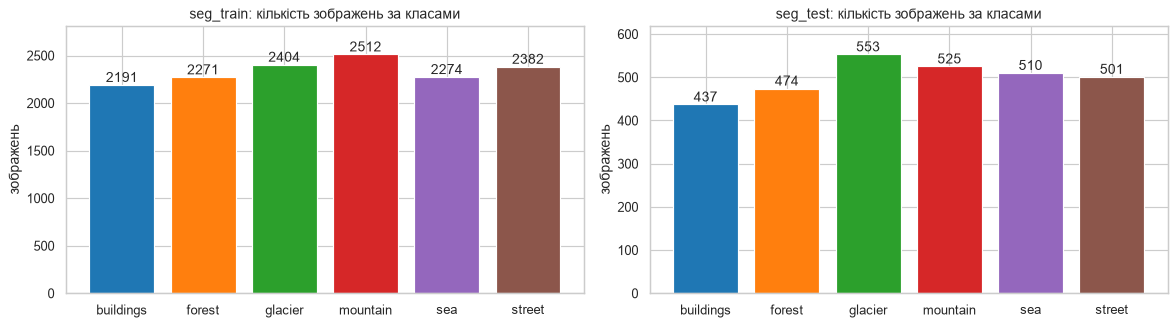

In [3]:
base_train = datasets.ImageFolder(TRAIN_DIR)   # no transform: only the (path, label) list
base_test = datasets.ImageFolder(TEST_DIR)
CLASSES = base_train.classes
NUM_CLASSES = len(CLASSES)
assert base_test.classes == CLASSES, 'class folders differ between train and test'
pred_files = sorted(PRED_DIR.glob('*.jpg'))
CLASS_COLORS = dict(zip(CLASSES, sns.color_palette('tab10', NUM_CLASSES)))

counts = pd.DataFrame({'seg_train': np.bincount(base_train.targets, minlength=NUM_CLASSES),
                       'seg_test': np.bincount(base_test.targets, minlength=NUM_CLASSES)}, index=CLASSES)
counts['train, %'] = counts['seg_train'] / counts['seg_train'].sum() * 100
counts['test, %'] = counts['seg_test'] / counts['seg_test'].sum() * 100
display(counts.style.format({'train, %': '{:.1f}', 'test, %': '{:.1f}'}))
print(f'Класи (індекс -> назва): {dict(enumerate(CLASSES))}')
print(f'seg_train: {len(base_train):,} | seg_test: {len(base_test):,} | seg_pred (без міток): {len(pred_files):,}')
print(f'Дисбаланс (max/min): train {counts.seg_train.max() / counts.seg_train.min():.2f}, '
      f'test {counts.seg_test.max() / counts.seg_test.min():.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ['seg_train', 'seg_test']):
    bars = ax.bar(CLASSES, counts[col], color=[CLASS_COLORS[c] for c in CLASSES])
    ax.bar_label(bars)
    ax.set_title(f'{col}: кількість зображень за класами')
    ax.set_ylabel('зображень')
    ax.set_ylim(0, counts[col].max() * 1.12)
plt.tight_layout()
plt.show()

Висновок. Класи майже збалансовані: у train частки від 15.6 % (`buildings`) до 17.9 % (`mountain`), у test від 14.6 % до 18.4 %. Співвідношення max/min ≈ 1.15 і 1.27. Тому зважування класів у функції втрат чи oversampling не потрібні. Accuracy тут є змістовною метрикою, а macro-F1 додатково показує, чи не «провалюється» якийсь окремий клас (детальніше в розділі 5).

### 3.2 Приклади зображень кожного класу

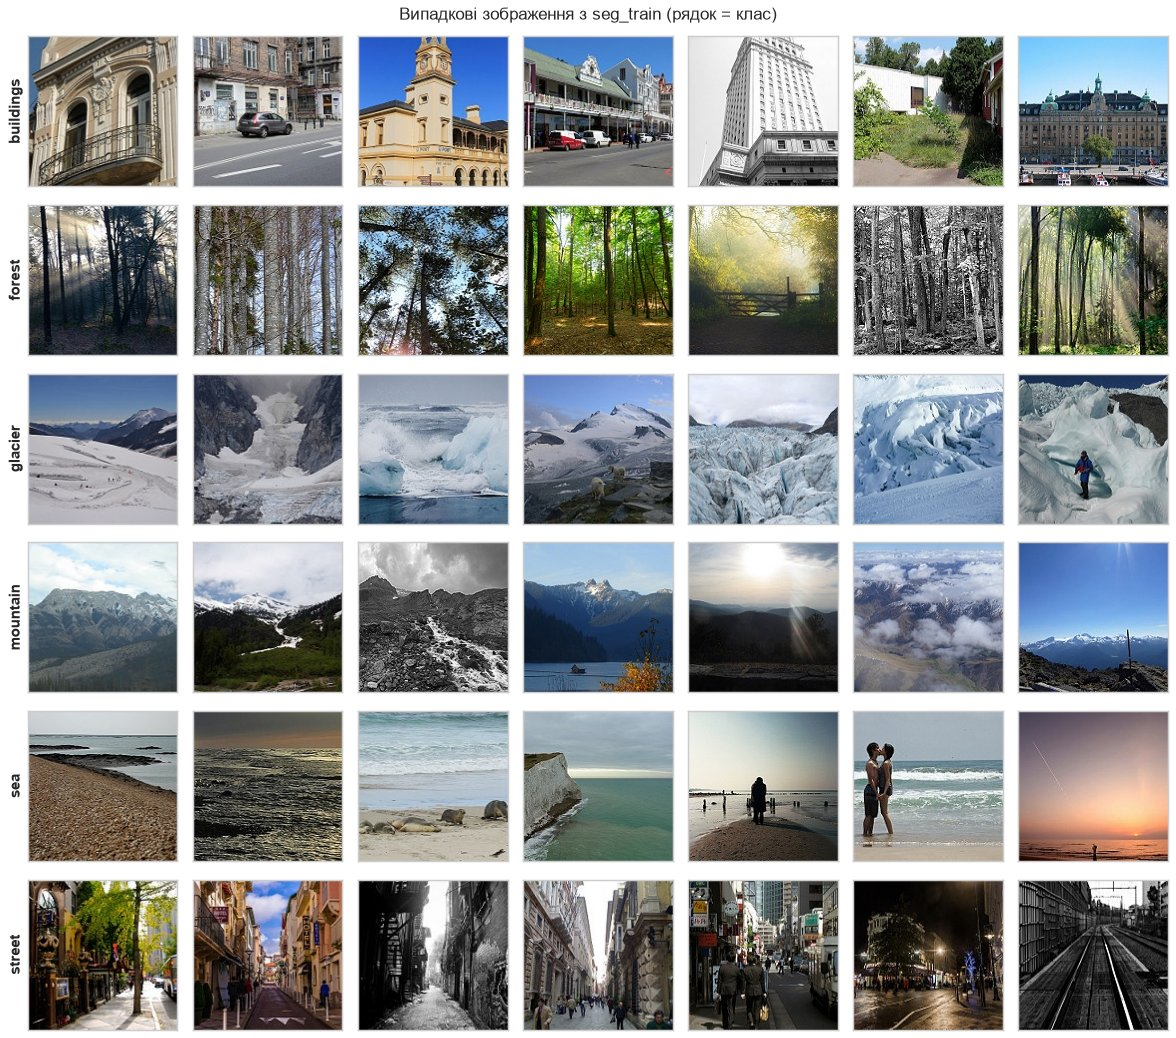

In [4]:
def load_rgb(path) -> np.ndarray:
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB'))


def show_photos(fig) -> None:
    """Display a figure of photos as JPEG: ~5x smaller notebook than PNG, no visible quality loss."""
    buf = BytesIO()
    fig.savefig(buf, format='jpeg', dpi=fig.dpi, bbox_inches='tight', pil_kwargs={'quality': 85})
    plt.close(fig)
    display(IPyImage(data=buf.getvalue(), format='jpeg'))


rng = np.random.default_rng(SEED)
train_targets = np.array(base_train.targets)
n_show = 7
fig, axes = plt.subplots(NUM_CLASSES, n_show, figsize=(14, 12.5))
for r, cls in enumerate(CLASSES):
    for c, i in enumerate(rng.choice(np.flatnonzero(train_targets == r), n_show, replace=False)):
        ax = axes[r, c]
        ax.imshow(load_rgb(base_train.samples[i][0]))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls, fontsize=13, fontweight='bold')
fig.suptitle('Випадкові зображення з seg_train (рядок = клас)', fontsize=14)
plt.tight_layout()
show_photos(fig)

Що з цього випливає для моделі:
* `forest`, `sea`, `street` і `buildings` мають характерні текстури та кольори, але деякі пари класів візуально перетинаються: `glacier` ↔ `mountain` (засніжені вершини є і там, і там), `buildings` ↔ `street` (на вулиці майже завжди є будівлі, а фасади часто знімають з вулиці), `sea` ↔ `glacier` (вода, лід, блакитна гамма).
* Клас визначає вся сцена (горизонт, небо, композиція), а не один обʼєкт у центрі. Я врахував це при виборі аугментацій: без сильного кропу і без вертикального відображення.

### 3.3 Розміри та формат зображень

`PIL.Image.open` читає лише заголовок файлу, тому перевірка всіх ~24 тис. зображень займає кілька секунд.

,зображень,150×150,інший розмір,"ширина, min–max","висота, min–max",кольорові режими
seg_train,14034,13986,48,150–150,76–150,RGB: 14034
seg_test,3000,2993,7,150–150,72–150,RGB: 3000
seg_pred,7301,7288,13,150–500,100–374,RGB: 7301


Найчастіші нестандартні розміри в seg_train (ширина×висота: к-сть): {(150, 113): np.int64(7), (150, 135): np.int64(3), (150, 111): np.int64(3), (150, 142): np.int64(2), (150, 108): np.int64(2), (150, 123): np.int64(2)}


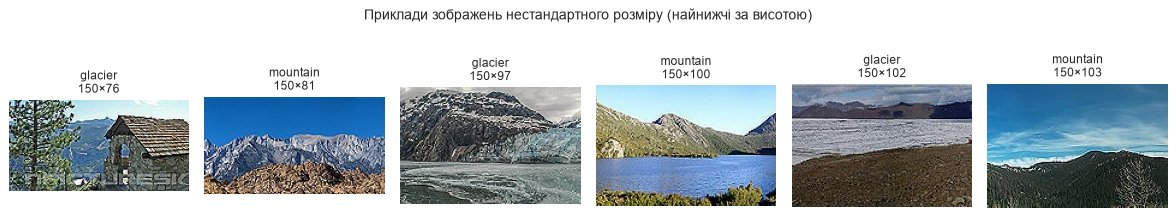

In [5]:
def scan_images(paths) -> pd.DataFrame:
    rows = []
    for p in paths:
        with Image.open(p) as im:
            rows.append((im.size[0], im.size[1], im.mode))
    return pd.DataFrame(rows, columns=['width', 'height', 'mode'])


size_info = {'seg_train': scan_images(p for p, _ in base_train.samples),
             'seg_test': scan_images(p for p, _ in base_test.samples),
             'seg_pred': scan_images(pred_files)}
size_summary = pd.DataFrame({
    name: {'зображень': len(df),
           '150×150': int(((df.width == 150) & (df.height == 150)).sum()),
           'інший розмір': int(((df.width != 150) | (df.height != 150)).sum()),
           'ширина, min–max': f'{df.width.min()}–{df.width.max()}',
           'висота, min–max': f'{df.height.min()}–{df.height.max()}',
           'кольорові режими': ', '.join(f'{k}: {v}' for k, v in df['mode'].value_counts().items())}
    for name, df in size_info.items()}).T
display(size_summary)

odd = size_info['seg_train'].query('width != 150 or height != 150')
print('Найчастіші нестандартні розміри в seg_train (ширина×висота: к-сть):',
      dict(odd.groupby(['width', 'height']).size().sort_values(ascending=False).head(6)))

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, i in zip(axes, odd.sort_values('height').index[:6]):
    path, label = base_train.samples[i]
    ax.imshow(load_rgb(path))
    ax.set_title(f'{CLASSES[label]}\n{odd.width[i]}×{odd.height[i]}', fontsize=10)
    ax.axis('off')
fig.suptitle('Приклади зображень нестандартного розміру (найнижчі за висотою)', fontsize=12)
plt.tight_layout()
show_photos(fig)

Висновок. Усі зображення в режимі RGB. У train і test ширина завжди 150 px, але 48 файлів у train і 7 у test мають меншу висоту (аж до 76 і 72 px). У немаркованому `seg_pred` є 13 нестандартних файлів, серед них і більші, до 500×374. У батчі всі тензори мусять мати однаковий розмір, тому кожен пайплайн починається з `Resize` до фіксованого розміру. Невелике розтягнення цих ~0.3 % зображень не шкодить.

### 3.4 Дублікати та суперечливі мітки

Порівнюємо MD5-хеші вмісту файлів: однаковий хеш = побайтово ідентичне зображення. Це перевіряє (1) витік даних між train і test та (2) узгодженість розмітки.

Груп побайтових дублікатів: 18  (зображень у них: 36)
  з них із РІЗНИМИ мітками: 13
  спільних для train і test: 3 (з різними мітками: 3)


,splits,labels,n_labels,files
0,seg_train + seg_train,glacier / mountain,2,"8191.jpg, 16696.jpg"
1,seg_train + seg_train,mountain / sea,2,"7037.jpg, 6337.jpg"
2,seg_train + seg_train,glacier / mountain,2,"10234.jpg, 7654.jpg"
3,seg_train + seg_train,buildings / street,2,"5069.jpg, 2764.jpg"
4,seg_train + seg_train,glacier / mountain,2,"16827.jpg, 15770.jpg"
5,seg_train + seg_train,buildings / street,2,"4551.jpg, 1495.jpg"
6,seg_train + seg_train,glacier / mountain,2,"19319.jpg, 6518.jpg"
7,seg_train + seg_train,buildings / street,2,"9769.jpg, 7293.jpg"
8,seg_train + seg_train,glacier / mountain,2,"16044.jpg, 17775.jpg"
9,seg_train + seg_train,glacier / mountain,2,"8608.jpg, 19959.jpg"


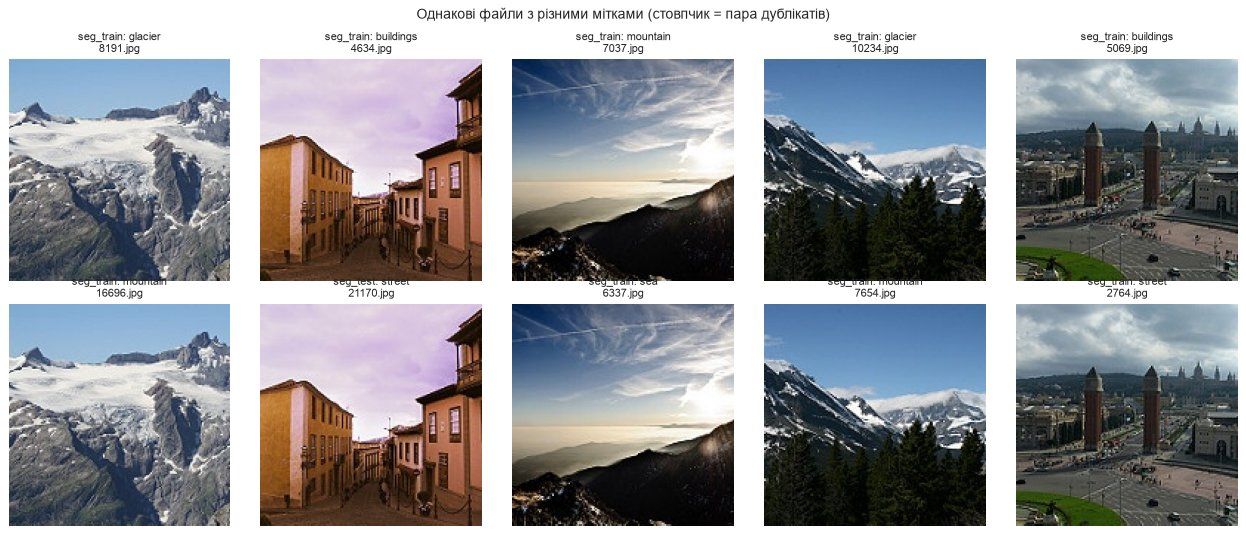

In [6]:
def md5(path) -> str:
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


files_df = pd.DataFrame(
    [('seg_train', p, CLASSES[y]) for p, y in base_train.samples] + [('seg_test', p, CLASSES[y]) for p, y in base_test.samples],
    columns=['split', 'path', 'label'])
files_df['md5'] = files_df['path'].map(md5)
dup = files_df[files_df.duplicated('md5', keep=False)].copy()
groups = dup.groupby('md5').agg(splits=('split', lambda s: ' + '.join(sorted(s))),
                                labels=('label', lambda s: ' / '.join(sorted(s))),
                                n_labels=('label', 'nunique'),
                                files=('path', lambda s: ', '.join(Path(p).name for p in s)))
print(f'Груп побайтових дублікатів: {len(groups)}  (зображень у них: {len(dup)})')
print(f'  з них із РІЗНИМИ мітками: {(groups.n_labels > 1).sum()}')
print(f'  спільних для train і test: {groups.splits.str.contains("seg_test").sum()} '
      f'(з різними мітками: {((groups.n_labels > 1) & groups.splits.str.contains("seg_test")).sum()})')
display(groups.sort_values(['n_labels', 'splits'], ascending=False).reset_index(drop=True))

# test files that have an identical copy with ANOTHER label (used later to mark errors)
conflict_md5 = set(groups.index[groups.n_labels > 1])
CONFLICT_TEST_FILES = set(files_df.query('split == "seg_test" and md5 in @conflict_md5')['path'])

conf_groups = [g for _, g in dup[dup.md5.isin(conflict_md5)].groupby('md5')][:5]
fig, axes = plt.subplots(2, len(conf_groups), figsize=(3 * len(conf_groups), 6.4))
for c, g in enumerate(conf_groups):
    for r in range(2):
        row = g.iloc[r]
        axes[r, c].imshow(load_rgb(row.path))
        axes[r, c].set_title(f'{row.split}: {row.label}\n{Path(row.path).name}', fontsize=9)
        axes[r, c].axis('off')
fig.suptitle('Однакові файли з різними мітками (стовпчик = пара дублікатів)', fontsize=12)
plt.tight_layout()
show_photos(fig)

Висновок. Знайдено 18 груп побайтових дублікатів, і в 13 з них мітки різні. Отже, у розмітці є шум, причому саме в тих парах класів, які візуально перетинаються (`buildings`/`street`, `glacier`/`mountain`). Три тестові зображення мають точну копію в train з іншою міткою. Модель, яка «запамʼятала» train-версію, на них гарантовано помилиться за тестовою міткою.

Test я не змінюю, щоб результати можна було порівнювати з іншими роботами на цьому датасеті. Train теж не чищу: 13 конфліктних пар (0.1 % даних) практично не впливають на навчання. Натомість ці файли буде позначено в аналізі помилок (розділ 11). Побайтові дублікати дають лише нижню оцінку, бо майже-дублікати (інше стиснення, кроп) цим методом не знаходяться.

## 4. Розбиття train / validation та препроцесинг

### 4.1 Стратифікований поділ `seg_train` → train (85 %) / val (15 %)

* Дані вже поділені на `seg_train` і `seg_test`, але окремої валідаційної вибірки немає. Вона потрібна для ранньої зупинки, зменшення lr, збереження найкращої моделі та порівняння конфігурацій. Брати для цього test не можна, бо тоді оцінка стала б оптимістично зміщеною.
* 15 % ≈ 2.1 тис. зображень (~350 на клас). Стандартна похибка оцінки accuracy ≈ √(0.9·0.1/2100) ≈ 0.65 п.п. Цього достатньо, щоб розрізняти моделі, а для навчання лишається 85 % даних.
* Стратифікація за міткою зберігає однакові частки класів у train і val, а `random_state=SEED` робить поділ відтворюваним.

In [7]:
train_idx, val_idx = train_test_split(np.arange(len(base_train)), test_size=0.15,
                                      stratify=train_targets, random_state=SEED)
test_idx = np.arange(len(base_test))
test_targets = np.array(base_test.targets)
assert set(train_idx).isdisjoint(val_idx)

In [8]:
split_counts = pd.DataFrame({'train': np.bincount(train_targets[train_idx], minlength=NUM_CLASSES),
                             'val': np.bincount(train_targets[val_idx], minlength=NUM_CLASSES),
                             'test': np.bincount(test_targets[test_idx], minlength=NUM_CLASSES)}, index=CLASSES)
split_share = split_counts / split_counts.sum() * 100
display(pd.concat([split_counts, split_share.add_suffix(', %')], axis=1)
        .style.format('{:.1f}', subset=[c + ', %' for c in split_counts.columns]))
print(f'train: {len(train_idx):,} | val: {len(val_idx):,} | test: {len(test_idx):,}')

,train,val,test,"train, %","val, %","test, %"
buildings,1862,329,437,15.6,15.6,14.6
forest,1930,341,474,16.2,16.2,15.8
glacier,2043,361,553,17.1,17.1,18.4
mountain,2135,377,525,17.9,17.9,17.5
sea,1933,341,510,16.2,16.2,17.0
street,2025,357,501,17.0,17.0,16.7


train: 11,928 | val: 2,106 | test: 3,000


### 4.2 Статистики для нормалізації

* Для варіанту A (з нуля) середнє та стандартне відхилення по каналах R, G, B я рахую лише на train-частині, щоб не «підглядати» у val/test. Беру випадкову вибірку з 3 000 зображень, оцінка на ній стабільна до ~0.001. Після `Normalize` вхід має нульове середнє й одиничну дисперсію по каналах, і навчання йде швидше та стабільніше.
* Для варіанту B (ResNet18) використовую статистики ImageNet `(0.485, 0.456, 0.406) / (0.229, 0.224, 0.225)`. Ваги першого шару та статистики BatchNorm претренованої мережі розраховані саме на так нормалізовані входи. Інша нормалізація зсунула б розподіл активацій, і «готові» ознаки працювали б гірше.

In [9]:
stat_tf = T.Compose([T.Resize((150, 150)), T.ToTensor()])
stat_idx = np.random.default_rng(SEED).choice(train_idx, size=min(3000, len(train_idx)), replace=False)
ch_sum, ch_sq, n_px = torch.zeros(3, dtype=torch.float64), torch.zeros(3, dtype=torch.float64), 0
for i in stat_idx:
    x = stat_tf(base_train.loader(base_train.samples[i][0])).double()
    ch_sum += x.sum(dim=(1, 2))
    ch_sq += (x ** 2).sum(dim=(1, 2))
    n_px += x.shape[1] * x.shape[2]
ch_mean = ch_sum / n_px
DATA_MEAN = [round(v, 4) for v in ch_mean.tolist()]
DATA_STD = [round(v, 4) for v in (ch_sq / n_px - ch_mean ** 2).sqrt().tolist()]
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
display(pd.DataFrame({'Intel train: mean': DATA_MEAN, 'Intel train: std': DATA_STD,
                      'ImageNet: mean': IMAGENET_MEAN, 'ImageNet: std': IMAGENET_STD}, index=['R', 'G', 'B']))

,Intel train: mean,Intel train: std,ImageNet: mean,ImageNet: std
R,0.4314,0.2694,0.4850,0.2290
G,0.4582,0.2679,0.4560,0.2240
B,0.4528,0.2987,0.4060,0.2250


Статистики Intel близькі до ImageNet (природні фото), але відрізняються: синій канал помітно вищий, а червоний нижчий (багато неба, води й льоду), стандартні відхилення теж більші (контрастні сцени з яскравим небом). Тому для мережі з нуля я використовую власні статистики, а для ResNet18 статистики ImageNet, на які розраховані її ваги.

### 4.3 Трансформації: окремі пайплайни для train і для val/test

| Крок | train (A і B) | val / test | Обґрунтування |
|---|---|---|---|
| `Resize((150,150))` | ✓ (перед кропом) | - | уніфікує ~0.3 % зображень нестандартного розміру |
| `RandomResizedCrop(size, scale=(0.7, 1.0), ratio=(0.9, 1.1))` | ✓ | - | варіативність масштабу й положення сцени; мінімум 70 % площі, щоб не відрізати визначальну частину (смугу моря, вершину гори) |
| `RandomHorizontalFlip(0.5)` | ✓ | - | сцени дзеркально-симетричні: відображена вулиця теж є вулицею |
| `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)` | ✓ | - | різна погода, освітлення, камери |
| `Resize((size, size))` | - | ✓ | детермінований пайплайн: оцінка щоразу однакова |
| `ToTensor` + `Normalize` | ✓ | ✓ | переведення в [0, 1] і стандартизація (див. 4.2) |

Деяких аугментацій я свідомо не використовую. Вертикальне відображення не підходить: небо завжди зверху, а «перевернуте море» схоже на небо чи льодовик, тобто аугментація змінила б семантику. Зміна відтінку (hue) теж не підходить, бо колір є ознакою класу (зелений ліс, синє море, білий лід). Великі повороти ламають лінію горизонту, яка є важливою ознакою, і додають чорні кути.

Розмір входу. Для A я залишаю рідні 150×150, бо для мережі з нуля немає сенсу штучно збільшувати зображення. Для B беру 224×224: ResNet18 навчена на ImageNet при 224, тож масштаб обʼєктів відносно рецептивних полів збігається з претренуванням (в експерименті 8 перевірю і 150×150). На val/test я не роблю `CenterCrop`, як у лекції (`Resize(256)` + `CenterCrop(224)`). У сценах 150×150 клас може визначатися краєм кадру, тому зображення масштабується повністю.

In [10]:
def build_transforms(size: int, mean, std, augment: bool) -> T.Compose:
    if augment:
        steps = [T.Resize((150, 150)),                                   # unify the few non-150x150 images
                 T.RandomResizedCrop(size, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
                 T.RandomHorizontalFlip(p=0.5),
                 T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)]
    else:
        steps = [T.Resize((size, size))]                                 # deterministic: val / test / clean train eval
    return T.Compose(steps + [T.ToTensor(), T.Normalize(mean, std)])


train_tf_A = build_transforms(150, DATA_MEAN, DATA_STD, augment=True)
eval_tf_A = build_transforms(150, DATA_MEAN, DATA_STD, augment=False)
train_tf_B = build_transforms(224, IMAGENET_MEAN, IMAGENET_STD, augment=True)
eval_tf_B = build_transforms(224, IMAGENET_MEAN, IMAGENET_STD, augment=False)
print('train (A):', train_tf_A, '\n\nval/test (A):', eval_tf_A, '\n\ntrain (B):', train_tf_B, '\n\nval/test (B):', eval_tf_B)

train (A): Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(150, 150), scale=(0.7, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.4314, 0.4582, 0.4528], std=[0.2694, 0.2679, 0.2987])
) 

val/test (A): Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.4314, 0.4582, 0.4528], std=[0.2694, 0.2679, 0.2987])
) 

train (B): Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    RandomResizedCrop(size=(224, 224), scale=(0.7, 1.0), ratio=(0.9, 1.1), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    N

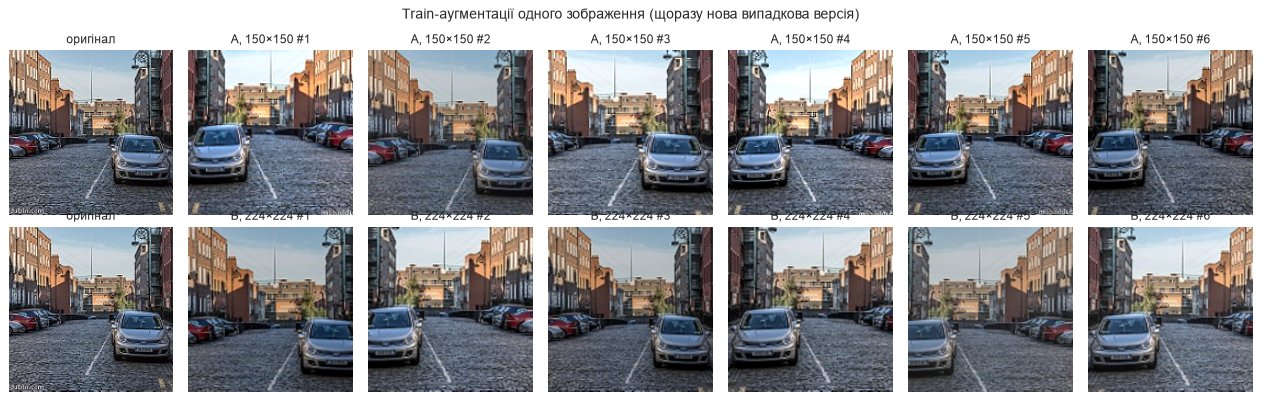

In [11]:
def denormalize(x: torch.Tensor, mean, std) -> np.ndarray:
    """CHW normalized tensor -> HWC array in [0, 1] for plt.imshow."""
    x = x * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


demo_i = train_idx[np.flatnonzero(train_targets[train_idx] == CLASSES.index('street'))[3]]
demo_img = base_train.loader(base_train.samples[demo_i][0])
torch.manual_seed(SEED)
fig, axes = plt.subplots(2, 7, figsize=(15, 4.8))
for r, (tf, mean, std, name) in enumerate([(train_tf_A, DATA_MEAN, DATA_STD, 'A, 150×150'),
                                           (train_tf_B, IMAGENET_MEAN, IMAGENET_STD, 'B, 224×224')]):
    axes[r, 0].imshow(demo_img)
    axes[r, 0].set_title('оригінал', fontsize=10)
    for c in range(1, 7):
        axes[r, c].imshow(denormalize(tf(demo_img), mean, std))
        axes[r, c].set_title(f'{name} #{c}', fontsize=10)
    for ax in axes[r]:
        ax.axis('off')
fig.suptitle('Train-аугментації одного зображення (щоразу нова випадкова версія)', fontsize=12)
plt.tight_layout()
show_photos(fig)

### 4.4 `ImageFolder` + `Subset` + `DataLoader`

`Subset` лише вибирає індекси, а трансформацію бере з базового датасету. Якби train і val були двома `Subset` одного `ImageFolder` з train-аугментаціями, валідація теж отримувала б випадкові кропи й кольори, і метрики були б шумними та зміщеними. Тому я створюю два «перегляди» однієї папки `seg_train` з різними трансформаціями і накладаю на них ті самі індекси поділу:

* `train`: `Subset(ImageFolder(seg_train, train_tf), train_idx)`, з аугментаціями, для навчання;
* `train_eval`: ті самі train-зображення без аугментацій, для «чистої» оцінки якості на train (розділ 10);
* `val`: `Subset(ImageFolder(seg_train, eval_tf), val_idx)`;
* `test`: `ImageFolder(seg_test, eval_tf)`.

Параметри `DataLoader`: `batch_size=64`, `shuffle=True` лише для train (з фіксованим генератором), `num_workers=4` і `persistent_workers`, щоб процеси-воркери не перезапускалися кожної епохи.

In [12]:
def make_datasets(train_tf, eval_tf) -> dict:
    train_aug_view = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)    # random augmentation
    train_eval_view = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)    # deterministic
    test_view = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
    return {'train': Subset(train_aug_view, train_idx),
            'train_eval': Subset(train_eval_view, train_idx),
            'val': Subset(train_eval_view, val_idx),
            'test': Subset(test_view, test_idx)}


def make_loader(ds, shuffle: bool = False, persistent: bool = False) -> DataLoader:
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      persistent_workers=persistent and NUM_WORKERS > 0,
                      multiprocessing_context=MP_CONTEXT if NUM_WORKERS > 0 else None,
                      generator=torch.Generator().manual_seed(SEED) if shuffle else None)


data_A = make_datasets(train_tf_A, eval_tf_A)
data_B = make_datasets(train_tf_B, eval_tf_B)
display(pd.DataFrame({k: [len(v)] for k, v in data_A.items()}, index=['зображень']))

x, y = next(iter(DataLoader(data_A['train'], batch_size=BATCH_SIZE, shuffle=True)))
print(f'Батч A: x {tuple(x.shape)} {x.dtype}, y {tuple(y.shape)} {y.dtype}; '
      f'після Normalize: mean по каналах {x.mean(dim=(0, 2, 3)).numpy().round(2)}, std {x.std(dim=(0, 2, 3)).numpy().round(2)}')
x, y = next(iter(DataLoader(data_B['val'], batch_size=BATCH_SIZE)))
print(f'Батч B (val): x {tuple(x.shape)}, мітки в батчі: {np.bincount(y.numpy(), minlength=NUM_CLASSES)}')

,train,train_eval,val,test
зображень,11928,11928,2106,3000


Батч A: x (64, 3, 150, 150) torch.float32, y (64,) torch.int64; після Normalize: mean по каналах [-0.    0.06  0.07], std [1.01 0.97 0.98]
Батч B (val): x (64, 3, 224, 224), мітки в батчі: [12 11  9 13 14  5]


## 5. Функція втрат, оптимізатор, метрики, гіперпараметри, цикл навчання

### 5.1 Функція втрат: `nn.CrossEntropyLoss`

* Задача є багатокласовою класифікацією з 6 взаємовиключними класами: кожне зображення має рівно одну мітку. Модель видає 6 логітів $z_k$. `CrossEntropyLoss` всередині застосовує `log_softmax` і рахує $-\log p_{y} = -z_y + \log\sum_k e^{z_k}$, тобто відʼємну лог-правдоподібність категоріального розподілу. Отже, навчання з цією функцією втрат є методом максимальної правдоподібності.
* Градієнт за логітами дорівнює $p - \text{onehot}(y)$. На відміну від MSE поверх softmax, він не «насичується», тому навчання не зупиняється на впевнено-хибних прикладах.
* Оскільки softmax уже є всередині функції втрат, модель не має softmax / log_softmax на виході і повертає лише логіти. У функції втрат обчислення йде через log-sum-exp і числово стабільне, а подвійний softmax був би помилкою. Ймовірності я рахую через `torch.softmax` лише під час інференсу.
* Класи майже збалансовані, тому ваги класів не потрібні. Label smoothing (корисний при шумних мітках) я залишив як ідею для покращення, щоб значення loss залишалися «чистою» крос-ентропією.

### 5.2 Оптимізатор: Adam

Adam адаптує крок для кожного параметра (через оцінки 1-го і 2-го моментів градієнта), стійкий до різного масштабу градієнтів у різних шарах і швидко збігається з типовим `lr=1e-3`. Для обмеженого числа епох він добре підходить. `weight_decay=1e-4` (L2-регуляризація) трохи обмежує ваги. Для fine-tuning претренованих шарів lr у 10 разів менший (`1e-4`), щоб не зруйнувати корисні ознаки ImageNet (catastrophic forgetting).

Планувальник `ReduceLROnPlateau` зменшує lr, коли val loss перестає падати (A: ×0.5 після 2 епох без покращення; B: ×0.3 після 1 епохи). На початку кроки великі, а в кінці модель доналаштовується дрібними кроками.

### 5.3 Метрики: accuracy та macro-F1

* Accuracy показує частку правильних відповідей. Вона інтуїтивна і коректна, коли класи майже рівні за розміром.
* Macro-F1 є середнім F1 по класах, де $F1 = 2PR/(P+R)$, гармонічне середнє precision і recall. Кожен клас має однакову вагу незалежно від розміру, тому метрика чутлива до «провалу» окремого класу. Наприклад, якщо `glacier` масово плутається з `mountain`, macro-F1 впаде сильніше, ніж accuracy. Також вона враховує обидва типи помилок: пропуски класу (recall) і хибні спрацювання (precision). При майже збалансованих класах macro-F1 ≈ accuracy, тож помітний розрив між ними вказує на проблему з конкретним класом.
* Чекпойнт і ранню зупинку я обираю за val macro-F1 (цільова метрика), а lr-планувальник працює за val loss, бо це плавніший сигнал.

### 5.4 Гіперпараметри

In [13]:
WEIGHT_DECAY = 1e-4       # light L2 regularisation for all runs
# Variant A: CNN from scratch
EPOCHS_A = 25             # max epochs; early stopping may stop earlier
PATIENCE_A = 5            # early stopping: epochs without val macro-F1 improvement
LR_A = 1e-3               # standard Adam lr for a BatchNorm network trained from scratch
DROPOUT_A = 0.3
# Variant B: ResNet18 transfer learning
EPOCHS_B_HEAD = 3         # stage 1: only the new linear head (converges in a few epochs)
LR_B_HEAD = 1e-3
EPOCHS_B_FT = 6           # stage 2: fine-tuning pretrained layers (few epochs are enough, more -> overfitting)
PATIENCE_B = 3
LR_B_FT = 1e-4            # 10x lower: adapt, don't destroy, the ImageNet features

criterion = nn.CrossEntropyLoss()   # expects raw logits + integer class labels

display(pd.DataFrame([
    ('batch_size', BATCH_SIZE, 'вміщується в памʼять GPU навіть для ResNet18@224; ~190 кроків/епоху; ≥32 прикладів — стабільні статистики BatchNorm'),
    ('optimizer', 'Adam', 'адаптивний крок, швидка збіжність (5.2)'),
    ('lr (A)', LR_A, 'типовий для Adam + BatchNorm з нуля; далі зменшується ReduceLROnPlateau'),
    ('lr (B, етап 1 / етап 2)', f'{LR_B_HEAD} / {LR_B_FT}', 'нова голова — звичайний lr; претреновані шари — у 10× менший'),
    ('weight_decay', WEIGHT_DECAY, 'легка L2-регуляризація'),
    ('epochs (A)', f'≤ {EPOCHS_A}, patience {PATIENCE_A}', 'мережі з нуля потрібно більше епох; early stopping зупиняє, коли val не росте'),
    ('epochs (B)', f'{EPOCHS_B_HEAD} + ≤ {EPOCHS_B_FT}, patience {PATIENCE_B}', 'претреновані ознаки адаптуються за кілька епох'),
    ('dropout (A)', DROPOUT_A, 'регуляризація голови класифікатора'),
], columns=['гіперпараметр', 'значення', 'обґрунтування']).set_index('гіперпараметр'))

,значення,обґрунтування
гіперпараметр,,
batch_size,64,вміщується в памʼять GPU навіть для ResNet18@2...
optimizer,Adam,"адаптивний крок, швидка збіжність (5.2)"
lr (A),0.0010,типовий для Adam + BatchNorm з нуля; далі змен...
"lr (B, етап 1 / етап 2)",0.001 / 0.0001,нова голова — звичайний lr; претреновані шари ...
weight_decay,0.0001,легка L2-регуляризація
epochs (A),"≤ 25, patience 5",мережі з нуля потрібно більше епох; early stop...
epochs (B),"3 + ≤ 6, patience 3",претреновані ознаки адаптуються за кілька епох
dropout (A),0.3000,регуляризація голови класифікатора


### 5.5 Цикл навчання з відстеженням прогресу

* `run_epoch` робить один прохід по loader. У режимі train це `zero_grad → forward → loss → backward → step`, у режимі оцінки `model.eval()` і вимкнені градієнти. Функція повертає середній loss, accuracy та macro-F1 за всю епоху: метрики рахуються по всіх прогнозах епохи, а не усереднюються по батчах. Loss накопичується на GPU без `.item()` на кожному кроці, щоб було менше синхронізацій.
* `fit` після кожної епохи запускає валідацію і крок планувальника. Якщо val macro-F1 покращився, `state_dict` зберігається у `checkpoints/`. Після `patience` епох без покращення спрацьовує рання зупинка, а наприкінці завантажуються найкращі ваги. Для кожної епохи в лог пишуться train/val loss, accuracy, macro-F1, lr і час.
* Train-метрики в лозі рахуються «на льоту», з аугментаціями, dropout і вагами, що змінюються протягом епохи, тому вони занижені. «Чисті» train-метрики будуть у розділі 10.
* Запобіжники. Якщо loss стає NaN/Inf, навчання зупиняється з помилкою, а в розділі 9 кожен фінальний чекпойнт має відтворити свій val-результат із логу. Це захищає від тихих збоїв обчислень. На спільному Apple GPU, коли паралельно працюють інші важкі GPU-задачі, macOS може переривати командні буфери Metal (`kIOGPUCommandBufferCallbackErrorImpactingInteractivity`), і частина результатів виходить некоректною. Такий запуск треба просто повторити.
* Окремий момент у transfer learning: у замороженому backbone шари BatchNorm у режимі `train()` все одно оновлювали б свої running mean/var статистиками нового датасету. Функція `freeze_bn_stats` переводить у `eval()` ті BatchNorm-шари, чиї параметри заморожені, тому «заморожена» частина мережі не змінюється.

In [14]:
def freeze_bn_stats(model: nn.Module) -> None:
    """Keep running statistics of frozen BatchNorm layers (all their params have requires_grad=False)."""
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()


def run_epoch(model: nn.Module, loader: DataLoader, optimizer=None) -> dict:
    """One pass over `loader`: trains if an optimizer is given, otherwise evaluates. Epoch-level metrics."""
    is_train = optimizer is not None
    model.train(is_train)
    if is_train:
        freeze_bn_stats(model)
    loss_sum, preds, trues = torch.zeros((), device=DEVICE), [], []
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            loss_sum += loss.detach() * y.size(0)
            preds.append(logits.argmax(dim=1))
            trues.append(y)
    y_pred, y_true = torch.cat(preds).cpu().numpy(), torch.cat(trues).cpu().numpy()
    if not torch.isfinite(loss_sum):
        raise FloatingPointError('loss is NaN/Inf: training diverged or the GPU returned corrupted results '
                                 '(on a shared Apple GPU: rerun when no other GPU jobs are active)')
    return {'loss': loss_sum.item() / len(y_true), 'acc': accuracy_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}


def fit(model, data, optimizer, epochs, ckpt_path, tag, scheduler=None, patience=None, best_f1=-1.0):
    """Train with per-epoch validation; keep the best-by-val-macro-F1 weights in `ckpt_path` and reload them."""
    train_loader = make_loader(data['train'], shuffle=True, persistent=True)
    val_loader = make_loader(data['val'], persistent=True)
    history, bad_epochs, t_start = [], 0, time.time()
    for epoch in range(1, epochs + 1):
        t0, lr = time.time(), optimizer.param_groups[0]['lr']
        tr = run_epoch(model, train_loader, optimizer)
        va = run_epoch(model, val_loader)
        if scheduler is not None:
            scheduler.step(va['loss'])
        improved = va['f1'] > best_f1 + 1e-4
        if improved:
            best_f1, bad_epochs = va['f1'], 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            bad_epochs += 1
        history.append({'epoch': epoch, 'lr': lr, **{f'train_{k}': v for k, v in tr.items()},
                        **{f'val_{k}': v for k, v in va.items()}, 'epoch_time_s': time.time() - t0})
        print(f'[{tag}] {epoch:02d}/{epochs} | train loss {tr["loss"]:.4f} acc {tr["acc"]:.4f} F1 {tr["f1"]:.4f} | '
              f'val loss {va["loss"]:.4f} acc {va["acc"]:.4f} F1 {va["f1"]:.4f} | lr {lr:.2e} | {time.time() - t0:3.0f} s'
              + ('  <- найкращий val F1, збережено' if improved else ''))
        if patience is not None and bad_epochs >= patience:
            print(f'[{tag}] рання зупинка: val macro-F1 не покращувався {patience} епох поспіль')
            break
    del train_loader, val_loader                 # shut down persistent DataLoader workers
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True))
    return pd.DataFrame(history), time.time() - t_start


def count_params(model: nn.Module):
    return (sum(p.numel() for p in model.parameters()),
            sum(p.numel() for p in model.parameters() if p.requires_grad))


RUNS = {}   # run name -> model, data, checkpoint, history, summary


def register_run(name, family, description, model, history, train_time, data, ckpt):
    history = history.reset_index(drop=True)
    best = history.loc[history['val_f1'].idxmax()]
    total, trainable = count_params(model)
    RUNS[name] = dict(name=name, family=family, model=model, data=data, ckpt=ckpt, history=history, time=train_time,
                      summary={'run': name, 'варіант': family, 'опис': description, 'епох': len(history),
                               'найкраща епоха': int(best.name) + 1, 'val loss': best['val_loss'],
                               'val accuracy': best['val_acc'], 'val macro-F1': best['val_f1'],
                               'train acc (з аугм.)': best['train_acc'], 'параметрів, млн': total / 1e6,
                               'навчалося, млн': trainable / 1e6, 'час навчання, хв': train_time / 60})
    s = RUNS[name]['summary']
    print(f'==> {name}: найкраща епоха {s["найкраща епоха"]}/{s["епох"]}, val accuracy {s["val accuracy"]:.4f}, '
          f'val macro-F1 {s["val macro-F1"]:.4f}, час {s["час навчання, хв"]:.1f} хв')


def plot_history(name: str) -> None:
    h = RUNS[name]['history']
    x = np.arange(1, len(h) + 1)
    best = int(h['val_f1'].idxmax()) + 1
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, key, title in zip(axes, ['loss', 'acc', 'f1'], ['CrossEntropy loss', 'Accuracy', 'Macro-F1']):
        ax.plot(x, h[f'train_{key}'], 'o-', label='train (з аугментаціями)')
        ax.plot(x, h[f'val_{key}'], 's-', label='val')
        ax.axvline(best, color='gray', ls=':', label=f'найкращий чекпойнт (епоха {best})')
        if 'stage' in h and h['stage'].nunique() > 1:
            ax.axvline((h['stage'] == 1).sum() + 0.5, color='tab:red', ls='--', label='етап 1 → етап 2')
        ax.set_title(title)
        ax.set_xlabel('епоха')
        ax.set_xticks(x)
    axes[0].legend(fontsize=9)
    fig.suptitle(f'Криві навчання: {name}', fontsize=13)
    plt.tight_layout()
    plt.show()

## 6. Варіант A: згорткова мережа з нуля

### 6.1 Архітектура

VGG-подібна мережа з 4 згорткових блоків і голови класифікатора:

```
вхід 3×150×150
 └ блок 1: [Conv3×3(3→32) → BN → ReLU] → [Conv3×3(32→32) → BN → ReLU] → MaxPool2  → 32×75×75
 └ блок 2: ... 32→64 ...   → 64×37×37
 └ блок 3: ... 64→128 ...  → 128×18×18
 └ блок 4: ... 128→256 ... → 256×9×9
 └ AdaptiveAvgPool2d(1) → 256
 └ Dropout(0.3) → Linear(256→128) → ReLU → Dropout(0.3) → Linear(128→6)  = логіти
```

Чому саме така архітектура:
* Два згорткові шари 3×3 у блоці (ідея VGG) дають рецептивне поле 5×5 з меншою кількістю параметрів і додатковою нелінійністю. `padding=1` (same) зберігає розмір усередині блоку.
* BatchNorm після кожної згортки стабілізує розподіли активацій, тому можна брати lr = 1e-3 і швидше збігатися. BN також трохи регуляризує. Через це у згортках `bias=False`: зсув виконує BN.
* ReLU є простою нелінійністю без насичення для додатних значень.
* MaxPool 2×2 після блоку зменшує просторовий розмір удвічі, а кількість каналів подвоюється (32→256). Обчислення на блок приблизно однакові, а ознаки стають дедалі абстрактнішими (краї → текстури → частини сцени). Після 4 блоків рецептивне поле покриває більшу частину кадру.
* Global Average Pooling замість Flatten. `Flatten` дав би 256×9×9 = 20 736 ознак, і `Linear(20736, 128)` мав би 2.65 млн параметрів (більше, ніж уся згорткова частина) та схильність до перенавчання. GAP дає 256 ознак, робить модель інваріантнішою до положення обʼєктів у кадрі й дозволяє будь-який розмір входу.
* Dropout 0.3 у голові регуляризує модель, бо навчальних зображень лише ~12 тис.
* Разом ≈ 1.2 млн параметрів (для порівняння, у ResNet18 11.2 млн). Цієї ємності достатньо для 6 класів сцен, і таку мережу реально навчити з нуля за 20-25 епох.

In [15]:
def conv_bn_relu(c_in: int, c_out: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                         nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class ScratchCNN(nn.Module):
    """VGG-style CNN: 4 x [conv-bn-relu x2 + maxpool] -> global average pooling -> MLP head (returns logits)."""

    def __init__(self, num_classes: int = 6, channels=(32, 64, 128, 256), dropout: float = 0.3):
        super().__init__()
        blocks, c_in = [], 3
        for c_out in channels:
            blocks.append(nn.Sequential(conv_bn_relu(c_in, c_out), conv_bn_relu(c_out, c_out), nn.MaxPool2d(2)))
            c_in = c_out
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, 128), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.pool(self.features(x)))    # raw logits: softmax lives in the loss


demo_model = ScratchCNN(NUM_CLASSES, dropout=DROPOUT_A)
print(demo_model)
x = torch.zeros(1, 3, 150, 150)
rows = [('вхід', tuple(x.shape), 0)]
for i, block in enumerate(demo_model.features, 1):
    x = block(x)
    rows.append((f'блок {i}', tuple(x.shape), sum(p.numel() for p in block.parameters())))
x = demo_model.pool(x)
rows.append(('GAP', tuple(x.shape), 0))
rows.append(('класифікатор', tuple(demo_model.classifier(x).shape), sum(p.numel() for p in demo_model.classifier.parameters())))
display(pd.DataFrame(rows, columns=['шар', 'вихід (N, C, H, W)', 'параметрів']).set_index('шар'))
print(f'Усього параметрів: {count_params(demo_model)[0]:,}')
del demo_model

ScratchCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Sequential(
        (0): Conv2d(64, 64, kern

,"вихід (N, C, H, W)",параметрів
шар,,
вхід,"(1, 3, 150, 150)",0
блок 1,"(1, 32, 75, 75)",10208
блок 2,"(1, 64, 37, 37)",55552
блок 3,"(1, 128, 18, 18)",221696
блок 4,"(1, 256, 9, 9)",885760
GAP,"(1, 256, 1, 1)",0
класифікатор,"(1, 6)",33670


Усього параметрів: 1,206,886


### 6.2 Навчання варіанту A (з аугментаціями)

Adam (lr 1e-3, weight decay 1e-4), `ReduceLROnPlateau(factor=0.5, patience=2)` за val loss, до 25 епох з ранньою зупинкою (patience 5) за val macro-F1. Найкращий чекпойнт зберігається в `checkpoints/A_aug.pt`.

In [16]:
def train_scratch(run_name: str, description: str, data: dict) -> None:
    set_seed()
    model = ScratchCNN(NUM_CLASSES, dropout=DROPOUT_A).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_A, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
    ckpt = CKPT_DIR / f'{run_name}.pt'
    history, train_time = fit(model, data, optimizer, EPOCHS_A, ckpt, run_name, scheduler, PATIENCE_A)
    register_run(run_name, 'A', description, model, history, train_time, data, ckpt)


train_scratch('A_aug', 'CNN з нуля, 150×150, аугментації', data_A)

[A_aug] 01/25 | train loss 0.9625 acc 0.6074 F1 0.6051 | val loss 1.1862 acc 0.5366 F1 0.4860 | lr 1.00e-03 |  39 s  <- найкращий val F1, збережено


[A_aug] 02/25 | train loss 0.6856 acc 0.7474 F1 0.7479 | val loss 0.6009 acc 0.7949 F1 0.7956 | lr 1.00e-03 |  34 s  <- найкращий val F1, збережено


[A_aug] 03/25 | train loss 0.5799 acc 0.7884 F1 0.7893 | val loss 0.6011 acc 0.7773 F1 0.7658 | lr 1.00e-03 |  34 s


[A_aug] 04/25 | train loss 0.5202 acc 0.8127 F1 0.8137 | val loss 0.6193 acc 0.7711 F1 0.7706 | lr 1.00e-03 |  37 s


[A_aug] 05/25 | train loss 0.4994 acc 0.8188 F1 0.8199 | val loss 0.5642 acc 0.7934 F1 0.7927 | lr 1.00e-03 |  44 s


...

[A_aug] 21/25 | train loss 0.2621 acc 0.9066 F1 0.9076 | val loss 0.3033 acc 0.8946 F1 0.8949 | lr 5.00e-04 |  39 s


[A_aug] 22/25 | train loss 0.2731 acc 0.9049 F1 0.9059 | val loss 0.2945 acc 0.9008 F1 0.9017 | lr 5.00e-04 |  36 s


[A_aug] 23/25 | train loss 0.2564 acc 0.9090 F1 0.9098 | val loss 0.3434 acc 0.8913 F1 0.8929 | lr 5.00e-04 |  37 s


[A_aug] 24/25 | train loss 0.2336 acc 0.9182 F1 0.9190 | val loss 0.2786 acc 0.9069 F1 0.9078 | lr 2.50e-04 |  42 s  <- найкращий val F1, збережено


[A_aug] 25/25 | train loss 0.2250 acc 0.9209 F1 0.9217 | val loss 0.2850 acc 0.9060 F1 0.9077 | lr 2.50e-04 |  35 s
==> A_aug: найкраща епоха 24/25, val accuracy 0.9069, val macro-F1 0.9078, час 16.8 хв


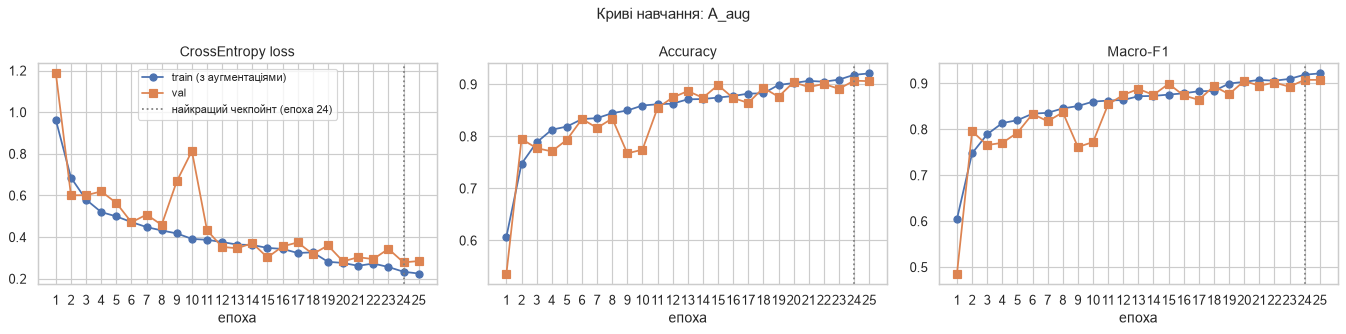

In [17]:
plot_history('A_aug')

Інтерпретація кривих (A). Train loss спадає монотонно (0.96 → 0.23), val loss загалом теж (1.19 → 0.28), але val-криві «зубчасті»: провали на епохах 3-4, 9-10 (val accuracy падає до 0.77) і 16-17. При lr 1e-3 ваги та статистики BatchNorm між епохами ще помітно змінюються, і якість на 2.1 тис. val-зображень то провалюється, то відновлюється. Коли `ReduceLROnPlateau` зменшує lr (1e-3 → 5e-4 після 18-ї епохи, далі до 2.5e-4 після 23-ї), коливання стихають. Саме для цього і потрібен планувальник. Train-метрики (з аугментаціями й dropout) і val майже збігаються (0.918 vs 0.907 на найкращій епосі). Перенавчання немає, модель радше недонавчена: найкращий чекпойнт припав на 24-ту епоху з 25 (val macro-F1 0.908), тож ще кілька епох із меншим lr трохи додали б. Рання зупинка не спрацювала, бо не було 5 епох поспіль без покращення.

## 7. Варіант B: трансферне навчання з ResNet18

Чому ResNet18. Residual-звʼязки (`y = F(x) + x`) дозволяють ефективно навчати глибокі мережі. ResNet18 є найлегшою моделлю родини (11.2 млн параметрів, 1.8 GFLOPs при 224×224) і добре підходить для ~12 тис. зображень та обмеженого часу навчання. Після претренування на ImageNet (1.28 млн фото, 1000 класів, серед яких є й сцени: узбережжя, гори, будівлі) мережа вже має низько- та середньорівневі ознаки (краї, текстури, частини обʼєктів), і вони переносяться на цю задачу.

Заміна голови. Останній шар `fc: Linear(512 → 1000)` я замінюю на `Linear(512 → 6)` під 6 класів датасету.

Навчання йде у два етапи:
1. Feature extraction. Backbone заморожений (`requires_grad=False`, BatchNorm-статистики теж), навчається лише нова голова (3 078 параметрів) з lr 1e-3. Випадково ініціалізована голова на старті дає великі градієнти. Якщо одразу розморозити всю мережу, вони «зіпсують» претреновані ваги, тому спершу я вчу тільки голову.
2. Fine-tuning. Я розморожую останній блок `layer4` (у ньому найвисокорівневіші й найспецифічніші для ImageNet ознаки) разом із головою і донавчаю з lr 1e-4, у 10 разів меншим. Ранні шари (краї, текстури) універсальні й лишаються замороженими. Так менший ризик перенавчання й catastrophic forgetting, а навчання йде швидше. Повне розморожування я порівнюю в розділі 8.

In [18]:
def build_resnet18() -> nn.Module:
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)   # ImageNet-pretrained weights
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)                  # new head: 512 -> 6 logits
    return model.to(DEVICE)


def set_trainable(model: nn.Module, prefixes) -> None:
    """requires_grad=True only for parameters whose name starts with one of `prefixes` ('' = the whole model)."""
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(tuple(prefixes))


tmp = build_resnet18()
set_trainable(tmp, ['fc'])
groups = ['conv1', 'bn1', 'layer1', 'layer2', 'layer3', 'layer4', 'fc']
display(pd.DataFrame([(g, sum(p.numel() for n, p in tmp.named_parameters() if n.startswith(g)),
                       'етап 1' if g == 'fc' else ('етап 2' if g == 'layer4' else 'заморожено'))
                      for g in groups], columns=['група шарів', 'параметрів', 'навчається']).set_index('група шарів'))
print(f'Параметрів усього: {count_params(tmp)[0]:,}; навчається на етапі 1: {count_params(tmp)[1]:,}')
del tmp

,параметрів,навчається
група шарів,,
conv1,9408,заморожено
bn1,128,заморожено
layer1,147968,заморожено
layer2,525568,заморожено
layer3,2099712,заморожено
layer4,8393728,етап 2
fc,3078,етап 1


Параметрів усього: 11,179,590; навчається на етапі 1: 3,078


### 7.1 Етап 1: заморожений backbone, навчається лише голова

In [19]:
def train_head(run_name: str, description: str, data: dict) -> None:
    set_seed()
    model = build_resnet18()
    set_trainable(model, ['fc'])
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=LR_B_HEAD, weight_decay=WEIGHT_DECAY)
    ckpt = CKPT_DIR / f'{run_name}.pt'
    history, train_time = fit(model, data, optimizer, EPOCHS_B_HEAD, ckpt, run_name)
    register_run(run_name, 'B', description, model, history.assign(stage=1), train_time, data, ckpt)


train_head('B_head', 'ResNet18@224: заморожений backbone, лише fc (етап 1)', data_B)

[B_head] 01/3 | train loss 0.5134 acc 0.8466 F1 0.8486 | val loss 0.3014 acc 0.8989 F1 0.9006 | lr 1.00e-03 |  29 s  <- найкращий val F1, збережено


[B_head] 02/3 | train loss 0.2746 acc 0.9058 F1 0.9074 | val loss 0.2591 acc 0.9160 F1 0.9175 | lr 1.00e-03 |  17 s  <- найкращий val F1, збережено


[B_head] 03/3 | train loss 0.2474 acc 0.9134 F1 0.9148 | val loss 0.2530 acc 0.9164 F1 0.9176 | lr 1.00e-03 |  17 s  <- найкращий val F1, збережено
==> B_head: найкраща епоха 3/3, val accuracy 0.9164, val macro-F1 0.9176, час 1.0 хв


### 7.2 Етап 2: fine-tuning `layer4` і голови з меншим lr

Стартую з найкращого чекпойнта етапу 1. Чекпойнт етапу 2 оновлюється лише тоді, коли val macro-F1 перевищує найкращий результат етапу 1. Тому `checkpoints/B_layer4.pt` містить найкращу модель за обидва етапи.

In [20]:
def finetune_from_head(run_name: str, description: str, head_run: str, trainable_prefixes, data: dict) -> None:
    set_seed()
    model = build_resnet18()
    model.load_state_dict(torch.load(RUNS[head_run]['ckpt'], map_location=DEVICE, weights_only=True))
    set_trainable(model, trainable_prefixes)
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR_B_FT, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=1)
    ckpt = CKPT_DIR / f'{run_name}.pt'
    shutil.copyfile(RUNS[head_run]['ckpt'], ckpt)            # start point = best stage-1 weights
    head_hist = RUNS[head_run]['history']
    history, train_time = fit(model, data, optimizer, EPOCHS_B_FT, ckpt, run_name, scheduler, PATIENCE_B,
                              best_f1=head_hist['val_f1'].max())
    register_run(run_name, 'B', description, model,
                 pd.concat([head_hist, history.assign(stage=2)], ignore_index=True),
                 RUNS[head_run]['time'] + train_time, data, ckpt)


finetune_from_head('B_layer4', 'ResNet18@224: етап 1 + fine-tuning layer4 і fc', 'B_head', ['layer4', 'fc'], data_B)

[B_layer4] 01/6 | train loss 0.2448 acc 0.9131 F1 0.9145 | val loss 0.2065 acc 0.9359 F1 0.9366 | lr 1.00e-04 |  30 s  <- найкращий val F1, збережено


[B_layer4] 02/6 | train loss 0.1421 acc 0.9474 F1 0.9483 | val loss 0.2032 acc 0.9368 F1 0.9378 | lr 1.00e-04 |  22 s  <- найкращий val F1, збережено


[B_layer4] 03/6 | train loss 0.1027 acc 0.9637 F1 0.9644 | val loss 0.2179 acc 0.9383 F1 0.9391 | lr 1.00e-04 |  22 s  <- найкращий val F1, збережено


[B_layer4] 04/6 | train loss 0.0784 acc 0.9728 F1 0.9733 | val loss 0.2163 acc 0.9345 F1 0.9356 | lr 1.00e-04 |  23 s


[B_layer4] 05/6 | train loss 0.0473 acc 0.9843 F1 0.9846 | val loss 0.2101 acc 0.9421 F1 0.9428 | lr 3.00e-05 |  24 s  <- найкращий val F1, збережено


[B_layer4] 06/6 | train loss 0.0356 acc 0.9893 F1 0.9895 | val loss 0.2085 acc 0.9421 F1 0.9430 | lr 3.00e-05 |  23 s  <- найкращий val F1, збережено
==> B_layer4: найкраща епоха 9/9, val accuracy 0.9421, val macro-F1 0.9430, час 3.4 хв


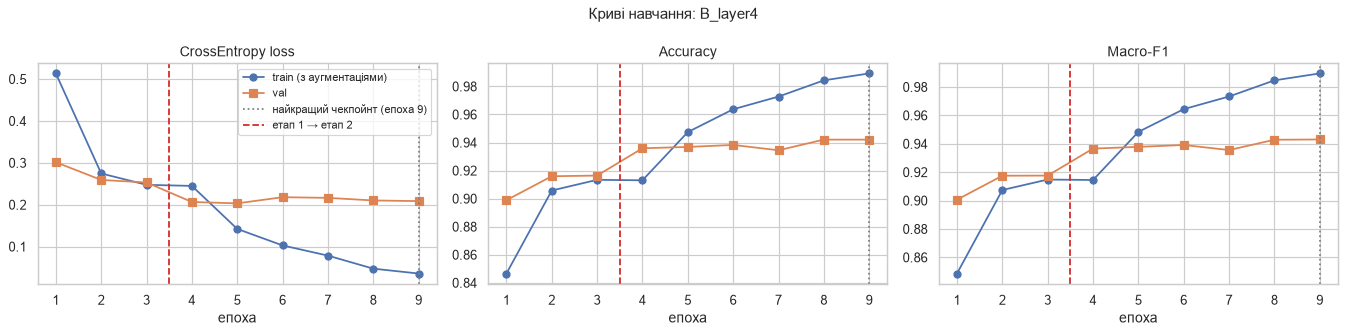

In [21]:
plot_history('B_layer4')

Інтерпретація кривих (B). На етапі 1 вже після першої епохи одна лінійна голова на заморожених ознаках ImageNet дає val macro-F1 0.90, а після трьох 0.918. Це більше, ніж у будь-якої з CNN з нуля за 25 епох (0.908 / 0.912), і приблизно в 16 разів швидше (1 хв проти 15-17 хв). Етап 2 починається після червоної лінії. Розморожування `layer4` з lr 1e-4 одразу додає ~2 п.п. (0.937 на першій же епосі), далі val виходить на плато ≈ 0.94, а train accuracy росте до 0.99. Тут починається перенавчання: val loss мінімальний на 2-й епосі етапу 2 й далі не падає. Тому короткий fine-tuning (≤ 6 епох), зменшення lr (1e-4 → 3e-5) і вибір чекпойнта за val були виправданими. Довше навчання лише збільшило б розрив між train і val.

## 8. Оптимізація (бонус): експерименти з аугментаціями, глибиною fine-tuning і роздільною здатністю

Кожен експеримент змінює один фактор відносно основної конфігурації. Порівнюю їх лише за validation, test тут не використовується.

| Run | Що змінюю | Питання |
|---|---|---|
| `A_noaug` | A без аугментацій (train = детермінований пайплайн) | наскільки аугментації стримують перенавчання мережі з нуля? |
| `B_full` | після етапу 1 розморожую всю ResNet18 (lr 1e-4) | чи варто адаптувати й ранні шари? |
| `B_full150` | як `B_full`, але вхід 150×150 замість 224×224 (обидва етапи) | чи потрібне збільшення зображень до розміру ImageNet? |

In [22]:
data_A_noaug = make_datasets(eval_tf_A, eval_tf_A)          # no augmentation at all
train_scratch('A_noaug', 'CNN з нуля, 150×150, БЕЗ аугментацій', data_A_noaug)

[A_noaug] 01/25 | train loss 0.8360 acc 0.6723 F1 0.6714 | val loss 0.9826 acc 0.6116 F1 0.5865 | lr 1.00e-03 |  43 s  <- найкращий val F1, збережено


[A_noaug] 02/25 | train loss 0.6045 acc 0.7763 F1 0.7773 | val loss 0.6753 acc 0.7493 F1 0.7466 | lr 1.00e-03 |  31 s  <- найкращий val F1, збережено


[A_noaug] 03/25 | train loss 0.5209 acc 0.8103 F1 0.8114 | val loss 0.4843 acc 0.8234 F1 0.8240 | lr 1.00e-03 |  33 s  <- найкращий val F1, збережено


[A_noaug] 04/25 | train loss 0.4803 acc 0.8239 F1 0.8251 | val loss 0.6021 acc 0.7896 F1 0.7748 | lr 1.00e-03 |  32 s


[A_noaug] 05/25 | train loss 0.4509 acc 0.8370 F1 0.8380 | val loss 0.4968 acc 0.8205 F1 0.8204 | lr 1.00e-03 |  32 s


...

[A_noaug] 21/25 | train loss 0.1799 acc 0.9385 F1 0.9394 | val loss 0.2848 acc 0.9088 F1 0.9095 | lr 6.25e-05 |  44 s  <- найкращий val F1, збережено


[A_noaug] 22/25 | train loss 0.1729 acc 0.9388 F1 0.9397 | val loss 0.2849 acc 0.9098 F1 0.9106 | lr 6.25e-05 |  44 s  <- найкращий val F1, збережено


[A_noaug] 23/25 | train loss 0.1664 acc 0.9441 F1 0.9449 | val loss 0.2785 acc 0.9107 F1 0.9114 | lr 3.13e-05 |  42 s  <- найкращий val F1, збережено


[A_noaug] 24/25 | train loss 0.1589 acc 0.9450 F1 0.9459 | val loss 0.2765 acc 0.9112 F1 0.9122 | lr 3.13e-05 |  43 s  <- найкращий val F1, збережено


[A_noaug] 25/25 | train loss 0.1544 acc 0.9476 F1 0.9484 | val loss 0.2828 acc 0.9107 F1 0.9117 | lr 3.13e-05 |  37 s
==> A_noaug: найкраща епоха 24/25, val accuracy 0.9112, val macro-F1 0.9122, час 15.5 хв


In [23]:
finetune_from_head('B_full', 'ResNet18@224: етап 1 + fine-tuning усієї мережі', 'B_head', [''], data_B)

[B_full] 01/6 | train loss 0.2543 acc 0.9107 F1 0.9120 | val loss 0.1975 acc 0.9364 F1 0.9371 | lr 1.00e-04 |  71 s  <- найкращий val F1, збережено


[B_full] 02/6 | train loss 0.1513 acc 0.9436 F1 0.9445 | val loss 0.2056 acc 0.9345 F1 0.9354 | lr 1.00e-04 |  79 s


[B_full] 03/6 | train loss 0.1155 acc 0.9591 F1 0.9598 | val loss 0.2396 acc 0.9288 F1 0.9292 | lr 1.00e-04 |  72 s


[B_full] 04/6 | train loss 0.0696 acc 0.9771 F1 0.9775 | val loss 0.1948 acc 0.9406 F1 0.9416 | lr 3.00e-05 |  77 s  <- найкращий val F1, збережено


[B_full] 05/6 | train loss 0.0476 acc 0.9842 F1 0.9845 | val loss 0.1955 acc 0.9449 F1 0.9457 | lr 3.00e-05 |  73 s  <- найкращий val F1, збережено


[B_full] 06/6 | train loss 0.0401 acc 0.9874 F1 0.9877 | val loss 0.1990 acc 0.9425 F1 0.9434 | lr 3.00e-05 |  74 s
==> B_full: найкраща епоха 8/9, val accuracy 0.9449, val macro-F1 0.9457, час 8.5 хв


In [24]:
train_tf_B150 = build_transforms(150, IMAGENET_MEAN, IMAGENET_STD, augment=True)
eval_tf_B150 = build_transforms(150, IMAGENET_MEAN, IMAGENET_STD, augment=False)
data_B150 = make_datasets(train_tf_B150, eval_tf_B150)
train_head('B_head150', 'ResNet18@150: заморожений backbone, лише fc (етап 1)', data_B150)
finetune_from_head('B_full150', 'ResNet18@150: етап 1 + fine-tuning усієї мережі', 'B_head150', [''], data_B150)

[B_head150] 01/3 | train loss 0.4875 acc 0.8435 F1 0.8453 | val loss 0.3039 acc 0.8936 F1 0.8948 | lr 1.00e-03 |  27 s  <- найкращий val F1, збережено


[B_head150] 02/3 | train loss 0.2766 acc 0.9016 F1 0.9031 | val loss 0.2781 acc 0.8989 F1 0.9001 | lr 1.00e-03 |  11 s  <- найкращий val F1, збережено


[B_head150] 03/3 | train loss 0.2584 acc 0.9070 F1 0.9085 | val loss 0.2689 acc 0.8970 F1 0.8985 | lr 1.00e-03 |  11 s
==> B_head150: найкраща епоха 2/3, val accuracy 0.8989, val macro-F1 0.9001, час 0.8 хв


[B_full150] 01/6 | train loss 0.2741 acc 0.9025 F1 0.9039 | val loss 0.2151 acc 0.9330 F1 0.9339 | lr 1.00e-04 |  50 s  <- найкращий val F1, збережено


[B_full150] 02/6 | train loss 0.1616 acc 0.9417 F1 0.9427 | val loss 0.2128 acc 0.9316 F1 0.9326 | lr 1.00e-04 |  34 s


[B_full150] 03/6 | train loss 0.1239 acc 0.9552 F1 0.9559 | val loss 0.2584 acc 0.9240 F1 0.9248 | lr 1.00e-04 |  31 s


[B_full150] 04/6 | train loss 0.0992 acc 0.9628 F1 0.9633 | val loss 0.2322 acc 0.9345 F1 0.9357 | lr 1.00e-04 |  31 s  <- найкращий val F1, збережено


[B_full150] 05/6 | train loss 0.0589 acc 0.9800 F1 0.9804 | val loss 0.2135 acc 0.9354 F1 0.9364 | lr 3.00e-05 |  29 s  <- найкращий val F1, збережено


[B_full150] 06/6 | train loss 0.0438 acc 0.9852 F1 0.9856 | val loss 0.2204 acc 0.9373 F1 0.9382 | lr 3.00e-05 |  35 s  <- найкращий val F1, збережено
==> B_full150: найкраща епоха 9/9, val accuracy 0.9373, val macro-F1 0.9382, час 4.3 хв


,варіант,опис,епох,найкраща епоха,val loss,val accuracy,val macro-F1,train acc (з аугм.),"параметрів, млн","навчалося, млн","час навчання, хв"
run,,,,,,,,,,,
A_aug,A,"CNN з нуля, 150×150, аугментації",25,24,0.2786,0.9069,0.9078,0.9182,1.21,1.207,16.8
B_head,B,"ResNet18@224: заморожений backbone, лише fc (етап 1)",3,3,0.2530,0.9164,0.9176,0.9134,11.18,0.003,1.0
B_layer4,B,ResNet18@224: етап 1 + fine-tuning layer4 і fc,9,9,0.2085,0.9421,0.9430,0.9893,11.18,8.397,3.4
A_noaug,A,"CNN з нуля, 150×150, БЕЗ аугментацій",25,24,0.2765,0.9112,0.9122,0.9450,1.21,1.207,15.5
B_full,B,ResNet18@224: етап 1 + fine-tuning усієї мережі,9,8,0.1955,0.9449,0.9457,0.9842,11.18,11.180,8.5
B_head150,B,"ResNet18@150: заморожений backbone, лише fc (етап 1)",3,2,0.2781,0.8989,0.9001,0.9016,11.18,0.003,0.8
B_full150,B,ResNet18@150: етап 1 + fine-tuning усієї мережі,9,9,0.2204,0.9373,0.9382,0.9852,11.18,11.180,4.3


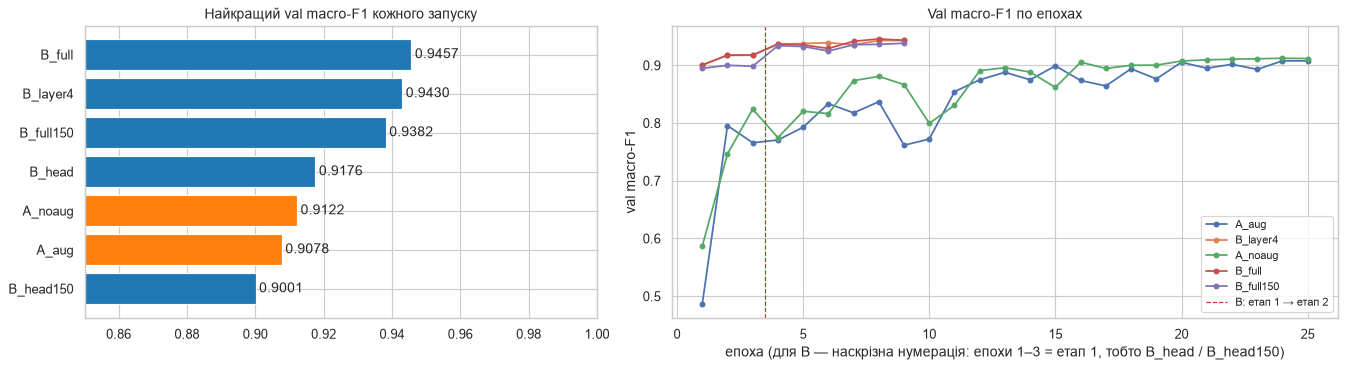

In [25]:
summary = pd.DataFrame([r['summary'] for r in RUNS.values()]).set_index('run')
display(summary.style.format({'val loss': '{:.4f}', 'val accuracy': '{:.4f}', 'val macro-F1': '{:.4f}',
                              'train acc (з аугм.)': '{:.4f}', 'параметрів, млн': '{:.2f}',
                              'навчалося, млн': '{:.3f}', 'час навчання, хв': '{:.1f}'})
        .background_gradient(subset=['val macro-F1'], cmap='Greens'))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.3]})
order = summary.sort_values('val macro-F1').index
bars = axes[0].barh(order, summary.loc[order, 'val macro-F1'],
                    color=['tab:orange' if summary.loc[r, 'варіант'] == 'A' else 'tab:blue' for r in order])
axes[0].bar_label(bars, fmt='%.4f', padding=3)
axes[0].set_xlim(summary['val macro-F1'].min() - 0.05, 1.0)
axes[0].set_title('Найкращий val macro-F1 кожного запуску')
for name, r in RUNS.items():
    if name.startswith('B_head'):      # stage-1 runs are the first 3 epochs of the fine-tuning curves
        continue
    axes[1].plot(np.arange(1, len(r['history']) + 1), r['history']['val_f1'], 'o-', ms=4, label=name)
axes[1].axvline(EPOCHS_B_HEAD + 0.5, color='tab:red', ls='--', lw=1, label='B: етап 1 → етап 2')
axes[1].set_xlabel('епоха (для B — наскрізна нумерація: епохи 1–3 = етап 1, тобто B_head / B_head150)')
axes[1].set_ylabel('val macro-F1')
axes[1].set_title('Val macro-F1 по епохах')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Результати експериментів.

Стандартна похибка val accuracy при 2 106 зображеннях ≈ ±0.5 п.п., тож менші різниці не варто вважати перевагою.

| Порівняння (val macro-F1) | Різниця | Висновок |
|---|---|---|
| A: з аугментаціями vs без (`A_aug` 0.908 vs `A_noaug` 0.912) | −0.4 п.п. | У межах шуму. Без аугментацій мережа сильніше «запамʼятовує» train (чиста train accuracy 0.960 проти val 0.911, розділ 10), а з аугментаціями train-метрики навіть на спотворених зображеннях ≈ val (0.918 vs 0.907). `A_noaug` уже збіглася (lr зменшено пʼять разів, до 3e-5), а `A_aug` мала lr 2.5e-4 і ще покращувалась, тобто при довшому навчанні має більший запас. До того ж навчання мережі з нуля на MPS не повністю детерміноване. У попередньому запуску цього самого ноутбука `A_noaug` зупинилася рано (11-та епоха, val F1 0.869) через «зубчасту» валідацію, а `A_aug` досягла 0.911. Отже, різниця між цими конфігураціями менша за розкид між запусками |
| B: лише голова vs fine-tuning `layer4` (`B_head` 0.918 → `B_layer4` 0.943) | +2.5 п.п. | адаптація високорівневих ознак ImageNet під сцени суттєво допомагає |
| B: `layer4` vs уся мережа (0.943 → `B_full` 0.946) | +0.3 п.п. | у межах похибки; повний fine-tuning у 2.5 раза довший (8.5 проти 3.4 хв) |
| B: 224×224 vs 150×150 (`B_full` 0.946 vs `B_full150` 0.938; етап 1: 0.918 vs 0.900) | +0.75 п.п. (етап 1: +1.75 п.п.) | збільшення до «рідного» розміру ImageNet допомагає, найбільше для заморожених ознак; після повного fine-tuning різниця на межі похибки, а навчання на 150×150 удвічі швидше |
| A vs B (найкраща A 0.912 vs `B_head` 0.918 / `B_full` 0.946) | +0.5 / +3.4 п.п. | перенесення знань вигідніше за навчання з нуля і за якістю, і за часом |

За val найкраща конфігурація `B_full`. `B_layer4` статистично від неї не відрізняється і в 2.5 раза дешевша.

### 8.1 Вибір фінальних моделей

Для кожного варіанту беру запуск із найкращим val macro-F1. На test оцінюються лише ці дві моделі.

In [26]:
final_A = max((r for r in RUNS.values() if r['family'] == 'A'), key=lambda r: r['summary']['val macro-F1'])
final_B = max((r for r in RUNS.values() if r['family'] == 'B'), key=lambda r: r['summary']['val macro-F1'])
FINAL = {'A': final_A, 'B': final_B}
for k, r in FINAL.items():
    print(f'Фінальна модель {k}: {r["name"]} ({r["summary"]["опис"]}), чекпойнт {r["ckpt"]}, '
          f'val macro-F1 {r["summary"]["val macro-F1"]:.4f}')

Фінальна модель A: A_noaug (CNN з нуля, 150×150, БЕЗ аугментацій), чекпойнт checkpoints/A_noaug.pt, val macro-F1 0.9122
Фінальна модель B: B_full (ResNet18@224: етап 1 + fine-tuning усієї мережі), чекпойнт checkpoints/B_full.pt, val macro-F1 0.9457


## 9. Оцінка на тестовому наборі

Фінальні моделі (найкращі за val чекпойнти) роблять прогнози на трьох вибірках: train (без аугментацій), val і test. Test-метрики наведено тут, а train і val знадобляться в розділі 10. Ймовірності рахуються як `softmax` від логітів.

In [27]:
@torch.no_grad()
def predict(model: nn.Module, ds) -> tuple:
    model.eval()
    probs, ys = [], []
    for x, y in make_loader(ds):
        probs.append(torch.softmax(model(x.to(DEVICE)), dim=1).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(probs).numpy()


SPLITS = {'train': 'train_eval', 'val': 'val', 'test': 'test'}
SPLIT_PATHS = {'train': [base_train.samples[i][0] for i in train_idx],
               'val': [base_train.samples[i][0] for i in val_idx],
               'test': [base_test.samples[i][0] for i in test_idx]}
PRED = {}
for key, run in FINAL.items():
    for split, ds_key in SPLITS.items():
        y_true, probs = predict(run['model'], run['data'][ds_key])
        PRED[key, split] = {'y_true': y_true, 'probs': probs, 'y_pred': probs.argmax(axis=1)}
    assert np.array_equal(PRED[key, 'test']['y_true'], test_targets[test_idx])
    val_f1 = f1_score(PRED[key, 'val']['y_true'], PRED[key, 'val']['y_pred'], average='macro', zero_division=0)
    print(f'{key}: val macro-F1 відтворено = {val_f1:.4f} (у лозі навчання: {run["summary"]["val macro-F1"]:.4f})')
    # sanity check: the reloaded checkpoint must reproduce its logged val score (guards against silent GPU errors)
    assert abs(val_f1 - run['summary']['val macro-F1']) < 2e-3, 'checkpoint does not reproduce its val score'


def metric_row(y_true, y_pred) -> dict:
    return {'accuracy': accuracy_score(y_true, y_pred),
            'macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'weighted-F1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
            'macro-precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
            'macro-recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
            'помилок': int((y_true != y_pred).sum())}


test_table = pd.DataFrame({f'{k}: {FINAL[k]["name"]}': metric_row(PRED[k, 'test']['y_true'], PRED[k, 'test']['y_pred'])
                           for k in FINAL}).T
test_table['помилок'] = test_table['помилок'].astype(int)
test_table['очікуваний діапазон accuracy'] = ['75–85 %', '90–97 %']
test_table['очікуваний діапазон F1'] = ['0.73–0.83', '0.89–0.96']
display(test_table.style.format({c: '{:.4f}' for c in ['accuracy', 'macro-F1', 'weighted-F1', 'macro-precision', 'macro-recall']}))

A: val macro-F1 відтворено = 0.9122 (у лозі навчання: 0.9122)


B: val macro-F1 відтворено = 0.9457 (у лозі навчання: 0.9457)


,accuracy,macro-F1,weighted-F1,macro-precision,macro-recall,помилок,очікуваний діапазон accuracy,очікуваний діапазон F1
A: A_noaug,0.9037,0.9049,0.9034,0.9046,0.9054,289,75–85 %,0.73–0.83
B: B_full,0.9417,0.9425,0.9414,0.9427,0.9429,175,90–97 %,0.89–0.96


In [28]:
for k in FINAL:
    p = PRED[k, 'test']
    print(f'===== {k}: {FINAL[k]["name"]} — classification report (test) =====')
    print(classification_report(p['y_true'], p['y_pred'], target_names=CLASSES, digits=4, zero_division=0))

===== A: A_noaug — classification report (test) =====
              precision    recall  f1-score   support

   buildings     0.8968    0.8947    0.8958       437
      forest     0.9688    0.9831    0.9759       474
     glacier     0.8692    0.8535    0.8613       553
    mountain     0.8655    0.8457    0.8555       525
         sea     0.9068    0.9353    0.9208       510
      street     0.9202    0.9202    0.9202       501

    accuracy                         0.9037      3000
   macro avg     0.9046    0.9054    0.9049      3000
weighted avg     0.9032    0.9037    0.9034      3000

===== B: B_full — classification report (test) =====
              precision    recall  f1-score   support

   buildings     0.9417    0.9245    0.9330       437
      forest     0.9853    0.9916    0.9884       474
     glacier     0.9395    0.8698    0.9033       553
    mountain     0.8891    0.9314    0.9098       525
         sea     0.9618    0.9882    0.9749       510
      street     0.9390  

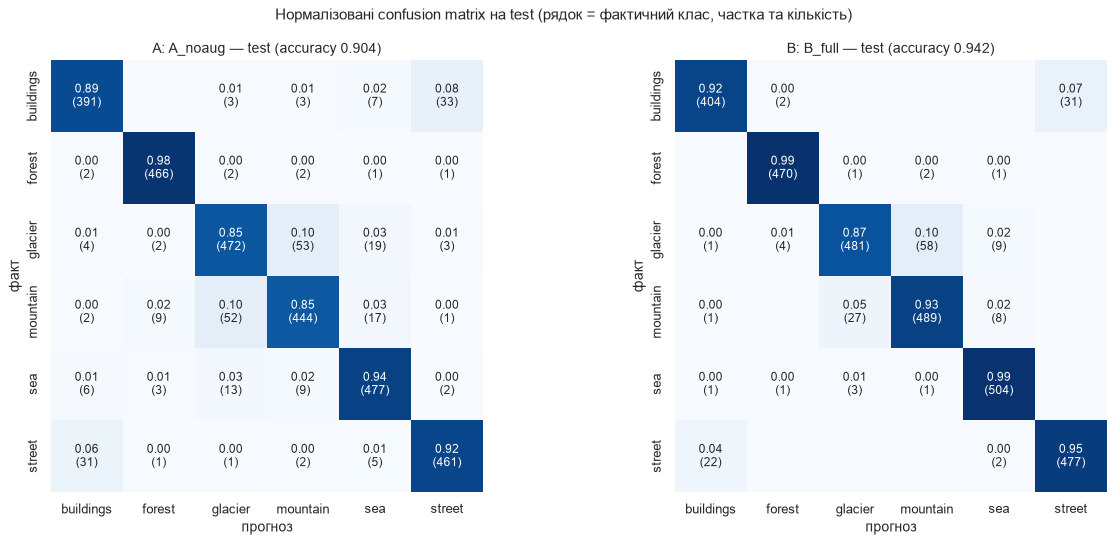

In [29]:
def plot_cm(ax, y_true, y_pred, title: str, fontsize: int = 10) -> None:
    """Confusion matrix normalised by true class (rows sum to 1 = recall); cells show share and count."""
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f'{cm_norm[i, j]:.2f}\n({cm[i, j]})' if cm[i, j] else '' for j in range(NUM_CLASSES)]
                      for i in range(NUM_CLASSES)])
    sns.heatmap(cm_norm, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1, cbar=False, square=True,
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={'fontsize': fontsize}, ax=ax)
    ax.set_xlabel('прогноз')
    ax.set_ylabel('факт')
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, k in zip(axes, FINAL):
    p = PRED[k, 'test']
    plot_cm(ax, p['y_true'], p['y_pred'], f'{k}: {FINAL[k]["name"]} — test (accuracy {accuracy_score(p["y_true"], p["y_pred"]):.3f})')
plt.suptitle('Нормалізовані confusion matrix на test (рядок = фактичний клас, частка та кількість)', fontsize=13)
plt.tight_layout()
plt.show()

Інтерпретація тестових метрик.

* A, CNN з нуля (`A_noaug`, обрана за val): accuracy 0.904, macro-F1 0.905. Це вище за орієнтовний діапазон 75-85 % / 0.73-0.83. Такий результат дали BatchNorm, глобальний пулінг і зменшення lr на плато.
* B, ResNet18 (етап 1 + повний fine-tuning): accuracy 0.942, macro-F1 0.943, усередині очікуваного діапазону 90-97 % / 0.89-0.96. Кількість помилок зменшилась з 289 до 175 (−39 %).
* Для обох моделей macro-F1 ≈ weighted-F1 ≈ accuracy, а macro-precision ≈ macro-recall. Класи збалансовані, жоден не «провалюється» повністю, і модель загалом не зміщена ні в бік пропусків, ні в бік хибних спрацювань.
* За класами (B) найлегші `forest` (F1 0.988) і `sea` (0.975), у них унікальна текстура й колір. Найважчі `glacier` (0.903, recall лише 0.87) і `mountain` (0.910), далі `buildings` (0.933). У A найслабші ті самі класи: `mountain` (0.856) і `glacier` (0.861). Найбільше transfer learning додає для `sea` і `mountain` (+5.4 п.п. F1) та `glacier` (+4.2 п.п.). За нормалізованою матрицею модель B називає горами 10 % льодовиків, а вулицями 7 % будівель.
* Test трохи нижчий за val (A −0.75 п.п., B −0.3 п.п.). У test більше найскладнішого класу `glacier` (18.4 % проти 17.1 %), а val має невеликий оптимістичний зсув, бо за ним обирали чекпойнт і конфігурацію.

## 10. Фактичні vs прогнозовані значення на train, validation і test

### 10.1 Метрики на трьох вибірках (узагальнення / перенавчання)

Train тут оцінюється без аугментацій (детермінований пайплайн), так само, як val і test.

In [30]:
rows = []
for k in FINAL:
    for split in SPLITS:
        p = PRED[k, split]
        rows.append({'модель': f'{k}: {FINAL[k]["name"]}', 'вибірка': split, 'зображень': len(p['y_true']),
                     **metric_row(p['y_true'], p['y_pred'])})
split_table = pd.DataFrame(rows).set_index(['модель', 'вибірка'])
display(split_table.style.format({c: '{:.4f}' for c in ['accuracy', 'macro-F1', 'weighted-F1', 'macro-precision', 'macro-recall']}))
for k in FINAL:
    acc = {s: accuracy_score(PRED[k, s]['y_true'], PRED[k, s]['y_pred']) for s in SPLITS}
    print(f'{k}: розрив train−val = {(acc["train"] - acc["val"]) * 100:+.2f} п.п., '
          f'train−test = {(acc["train"] - acc["test"]) * 100:+.2f} п.п., val−test = {(acc["val"] - acc["test"]) * 100:+.2f} п.п.')

A: розрив train−val = +4.92 п.п., train−test = +5.68 п.п., val−test = +0.75 п.п.
B: розрив train−val = +5.06 п.п., train−test = +5.38 п.п., val−test = +0.33 п.п.


### 10.2 Confusion matrix для train / val / test (обидві моделі)

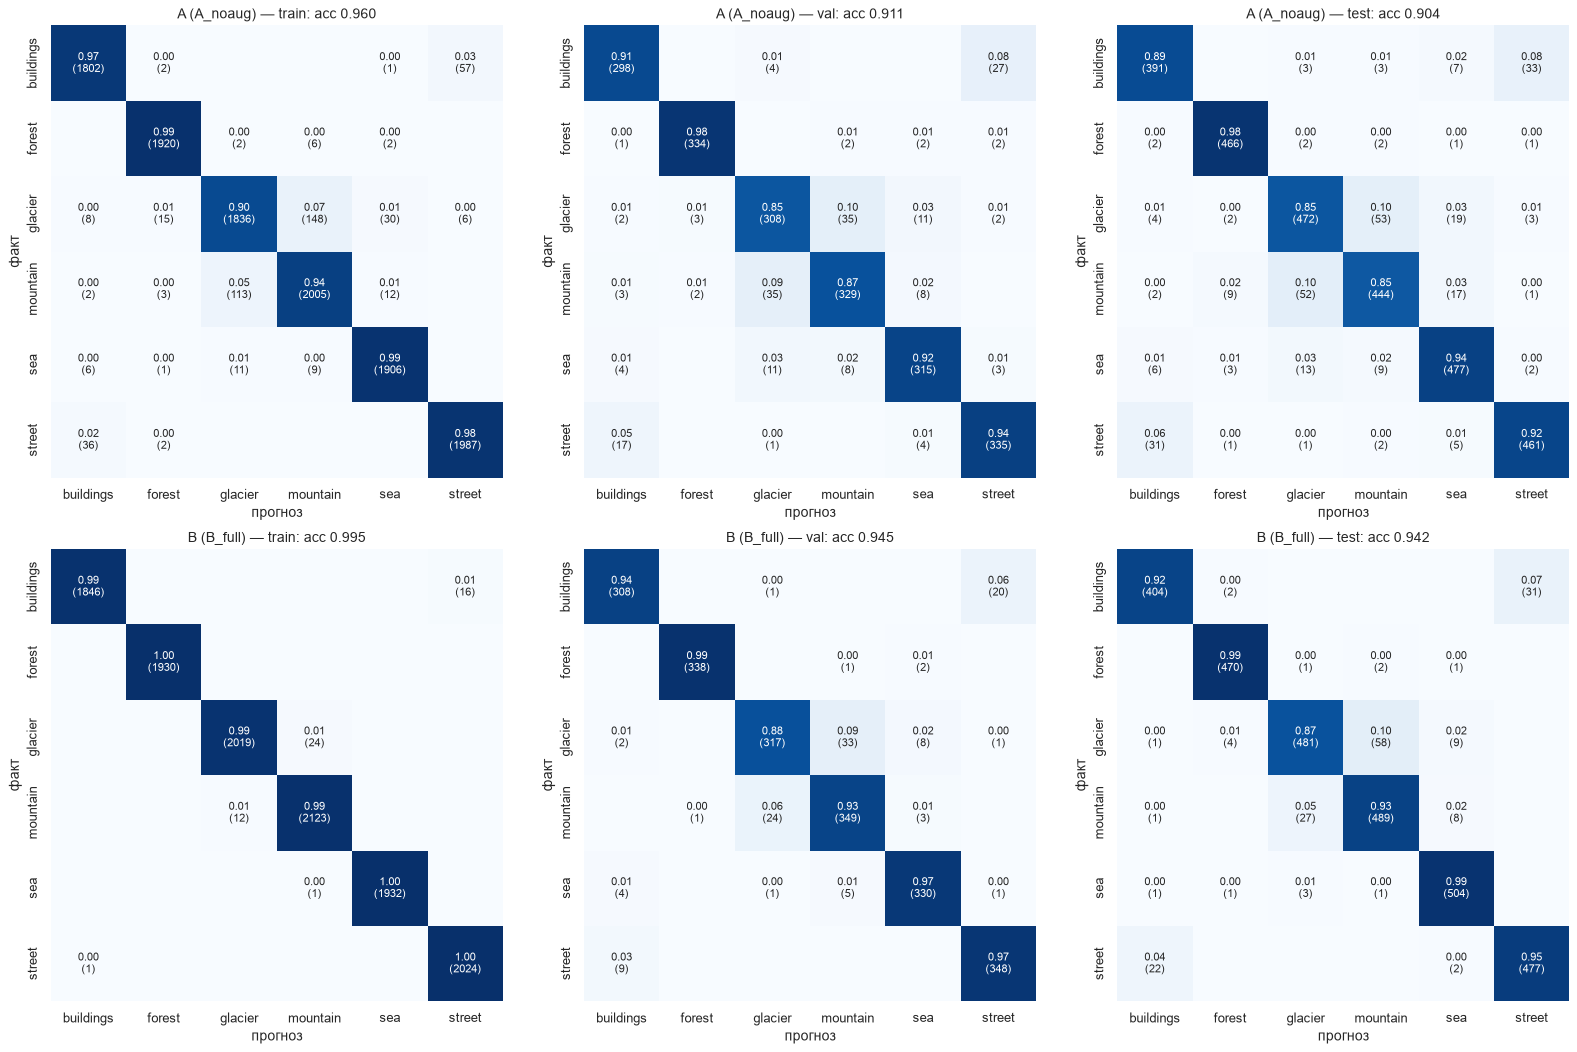

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(19, 12.5))
for r, k in enumerate(FINAL):
    for c, split in enumerate(SPLITS):
        p = PRED[k, split]
        plot_cm(axes[r, c], p['y_true'], p['y_pred'],
                f'{k} ({FINAL[k]["name"]}) — {split}: acc {accuracy_score(p["y_true"], p["y_pred"]):.3f}', fontsize=9)
plt.tight_layout()
plt.show()

### 10.3 Розподіл фактичних і прогнозованих класів

Якщо модель систематично «перетягує» зображення в якийсь клас, стовпчик прогнозів цього класу буде вищим за фактичний.

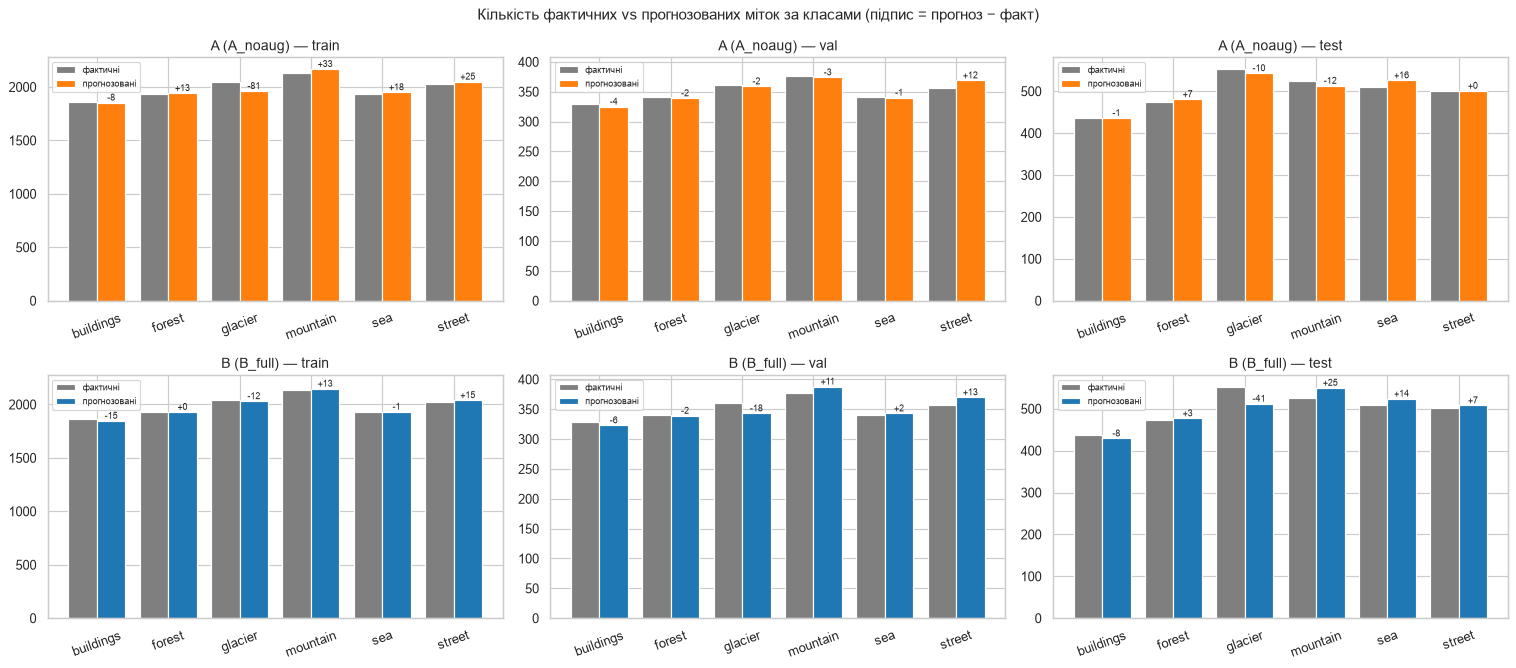

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey='col')
w = 0.4
for r, k in enumerate(FINAL):
    for c, split in enumerate(SPLITS):
        p, ax = PRED[k, split], axes[r, c]
        actual = np.bincount(p['y_true'], minlength=NUM_CLASSES)
        predicted = np.bincount(p['y_pred'], minlength=NUM_CLASSES)
        xs = np.arange(NUM_CLASSES)
        ax.bar(xs - w / 2, actual, w, label='фактичні', color='tab:gray')
        ax.bar(xs + w / 2, predicted, w, label='прогнозовані', color='tab:orange' if k == 'A' else 'tab:blue')
        for xi, (a, b) in enumerate(zip(actual, predicted)):
            ax.annotate(f'{b - a:+d}', (xi + w / 2, b), ha='center', va='bottom', fontsize=8)
        ax.set_xticks(xs, CLASSES, rotation=20)
        ax.set_title(f'{k} ({FINAL[k]["name"]}) — {split}')
        ax.legend(fontsize=8)
plt.suptitle('Кількість фактичних vs прогнозованих міток за класами (підпис = прогноз − факт)', fontsize=13)
plt.tight_layout()
plt.show()

### 10.4 Зображення з фактичними та прогнозованими мітками (фінальна модель B)

Для кожної вибірки 2 верхні ряди містять випадкові зображення (і правильні, і помилкові), а нижній ряд містить випадкові помилки. Зелений підпис означає правильний прогноз, червоний означає помилку. У дужках вказано ймовірність прогнозованого класу.

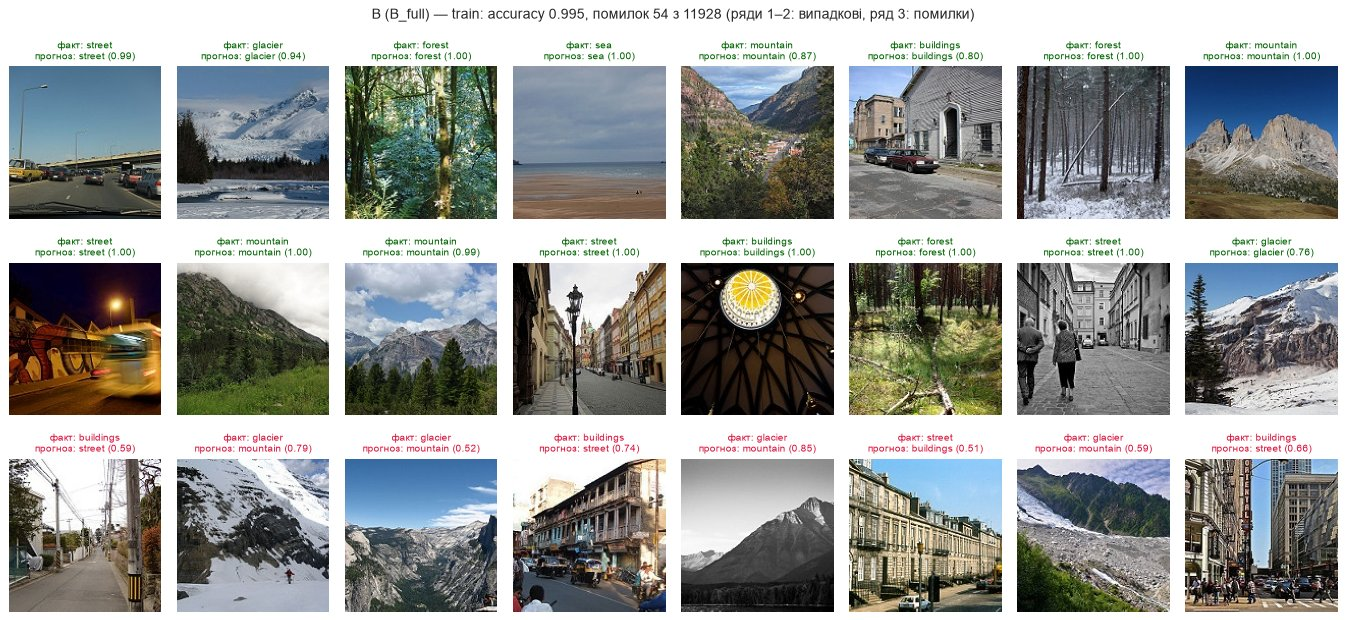

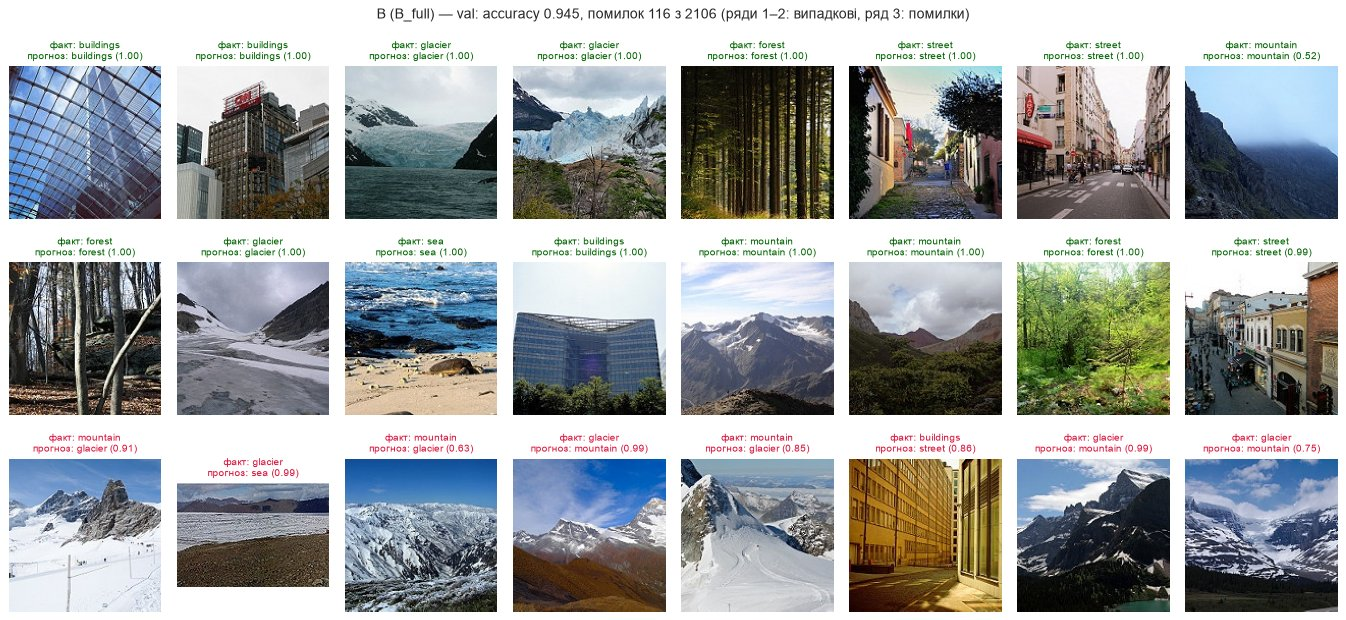

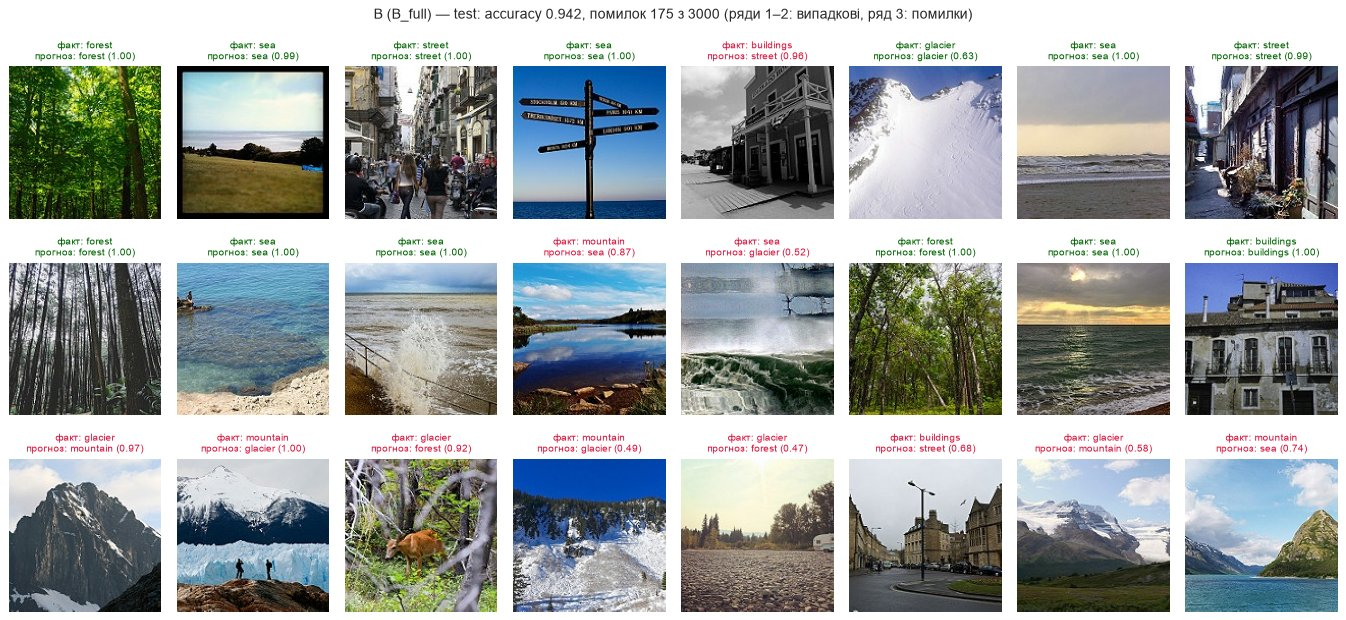

In [33]:
def show_grid(paths, items, ncols: int = 8, title: str = '', img_px: float = 2.0) -> None:
    """items: list of (index, title, is_correct)."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(img_px * ncols, (img_px + 0.55) * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (i, text, ok) in zip(axes.ravel(), items):
        ax.imshow(load_rgb(paths[i]))
        ax.set_title(text, fontsize=8.5, color='darkgreen' if ok else 'crimson')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    show_photos(fig)


def pred_items(p, idxs, extra=None):
    items = []
    for i in idxs:
        t, y = p['y_true'][i], p['y_pred'][i]
        text = f'факт: {CLASSES[t]}\nпрогноз: {CLASSES[y]} ({p["probs"][i, y]:.2f})'
        if extra:
            text += extra(i)
        items.append((i, text, t == y))
    return items


grid_rng = np.random.default_rng(SEED)
for split in SPLITS:
    p = PRED['B', split]
    wrong = np.flatnonzero(p['y_true'] != p['y_pred'])
    idxs = list(grid_rng.choice(len(p['y_true']), 16, replace=False)) + list(grid_rng.choice(wrong, min(8, len(wrong)), replace=False))
    show_grid(SPLIT_PATHS[split], pred_items(p, idxs),
              title=f'B ({final_B["name"]}) — {split}: accuracy {accuracy_score(p["y_true"], p["y_pred"]):.3f}, '
                    f'помилок {len(wrong)} з {len(p["y_true"])} (ряди 1–2: випадкові, ряд 3: помилки)')

### 10.5 Де моделі A і B розходяться (test)

,B правильно,B помиляється
A правильно,2651,60
A помиляється,174,115


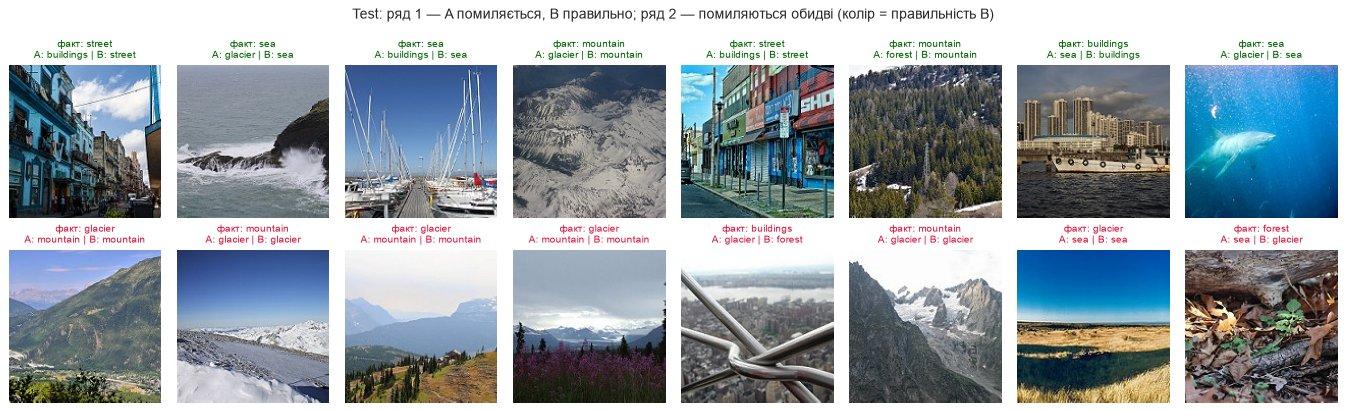

In [34]:
pa, pb = PRED['A', 'test'], PRED['B', 'test']
a_ok, b_ok = pa['y_true'] == pa['y_pred'], pb['y_true'] == pb['y_pred']
agreement = pd.DataFrame({'B правильно': [np.sum(a_ok & b_ok), np.sum(~a_ok & b_ok)],
                          'B помиляється': [np.sum(a_ok & ~b_ok), np.sum(~a_ok & ~b_ok)]},
                         index=['A правильно', 'A помиляється'])
display(agreement)

def ab_items(idxs):
    return [(i, f'факт: {CLASSES[pa["y_true"][i]]}\nA: {CLASSES[pa["y_pred"][i]]} | B: {CLASSES[pb["y_pred"][i]]}',
             b_ok[i]) for i in idxs]

ab_rng = np.random.default_rng(SEED)
fixed = np.flatnonzero(~a_ok & b_ok)
both = np.flatnonzero(~a_ok & ~b_ok)
show_grid(SPLIT_PATHS['test'], ab_items(list(ab_rng.choice(fixed, min(8, len(fixed)), replace=False)) +
                                        list(ab_rng.choice(both, min(8, len(both)), replace=False))),
          title='Test: ряд 1 — A помиляється, B правильно; ряд 2 — помиляються обидві (колір = правильність B)')

Інтерпретація (фактичні vs прогнозовані).

* A (`A_noaug`): train 0.960 / val 0.911 / test 0.904. Розрив train-val ≈ 5 п.п.: без аугментацій мережа частково запамʼятовує train-зображення.
* B: train 0.996 / val 0.945 / test 0.942, тобто майже ідеально на train і на ~5 п.п. гірше на нових даних. ResNet18 з 11 млн параметрів запамʼятовує train, хоча стартує з кращих ознак і тому має вищий рівень на всіх вибірках. Для обох моделей val і test майже збігаються (0.75 і 0.3 п.п.), отже val надійно передбачає якість на нових даних.
* Confusion matrix на всіх трьох вибірках мають однакову структуру: блоки `glacier`↔`mountain` і `buildings`↔`street` (у A ще й `glacier`/`mountain` → `sea`). Навіть на train у B майже половина з 54 помилок припадає на `glacier`→`mountain` (24). Це вказує на неоднозначність або шум міток, а не на нестачу даних.
* Розподіл прогнозів. На train A «недопрогнозовує» `glacier` (−81) на користь `mountain` (+33), на test її перекоси невеликі (±16). B на test систематично зсунута в бік `mountain` (+25) коштом `glacier` (−41), що узгоджується з recall 0.87 для `glacier` проти 0.93 для `mountain`.
* A vs B на test: B виправляє 174 помилки A і додає лише 60 нових. Для обох моделей помилковими є 115 зображень, здебільшого неоднозначні або неправильно розмічені (див. сітки вище та розділ 11).

## 11. Аналіз помилок

### 11.1 Найчастіші плутанини на test

In [35]:
def top_confusions(p, k: int = 8) -> pd.DataFrame:
    cm = confusion_matrix(p['y_true'], p['y_pred'], labels=range(NUM_CLASSES))
    n_err = cm.sum() - np.trace(cm)
    rows = [(CLASSES[i], CLASSES[j], cm[i, j], cm[i, j] / cm[i].sum() * 100, cm[i, j] / n_err * 100)
            for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
    return (pd.DataFrame(rows, columns=['факт', 'прогноз', 'помилок', '% від класу', '% усіх помилок'])
            .sort_values('помилок', ascending=False).head(k).reset_index(drop=True))


def pair_confusions(p) -> pd.Series:
    """Errors aggregated over unordered class pairs (A->B and B->A together)."""
    cm = confusion_matrix(p['y_true'], p['y_pred'], labels=range(NUM_CLASSES))
    pairs = {f'{CLASSES[i]} ↔ {CLASSES[j]}': cm[i, j] + cm[j, i]
             for i in range(NUM_CLASSES) for j in range(i + 1, NUM_CLASSES) if cm[i, j] + cm[j, i] > 0}
    s = pd.Series(pairs).sort_values(ascending=False)
    return pd.DataFrame({'помилок': s, '% усіх помилок': s / s.sum() * 100})


for k in FINAL:
    print(f'===== {k}: {FINAL[k]["name"]} =====')
    display(top_confusions(PRED[k, 'test']).style.format({'% від класу': '{:.1f}', '% усіх помилок': '{:.1f}'}))
    display(pair_confusions(PRED[k, 'test']).head(5).style.format({'% усіх помилок': '{:.1f}'}))

===== A: A_noaug =====


,факт,прогноз,помилок,% від класу,% усіх помилок
0,glacier,mountain,53,9.6,18.3
1,mountain,glacier,52,9.9,18.0
2,buildings,street,33,7.6,11.4
3,street,buildings,31,6.2,10.7
4,glacier,sea,19,3.4,6.6
5,mountain,sea,17,3.2,5.9
6,sea,glacier,13,2.5,4.5
7,mountain,forest,9,1.7,3.1


,помилок,% усіх помилок
glacier ↔ mountain,105,36.3
buildings ↔ street,64,22.1
glacier ↔ sea,32,11.1
mountain ↔ sea,26,9.0
buildings ↔ sea,13,4.5


===== B: B_full =====


,факт,прогноз,помилок,% від класу,% усіх помилок
0,glacier,mountain,58,10.5,33.1
1,buildings,street,31,7.1,17.7
2,mountain,glacier,27,5.1,15.4
3,street,buildings,22,4.4,12.6
4,glacier,sea,9,1.6,5.1
5,mountain,sea,8,1.5,4.6
6,glacier,forest,4,0.7,2.3
7,sea,glacier,3,0.6,1.7


,помилок,% усіх помилок
glacier ↔ mountain,85,48.6
buildings ↔ street,53,30.3
glacier ↔ sea,12,6.9
mountain ↔ sea,9,5.1
forest ↔ glacier,5,2.9


### 11.2 Приклади трьох найчастіших плутанин моделі B

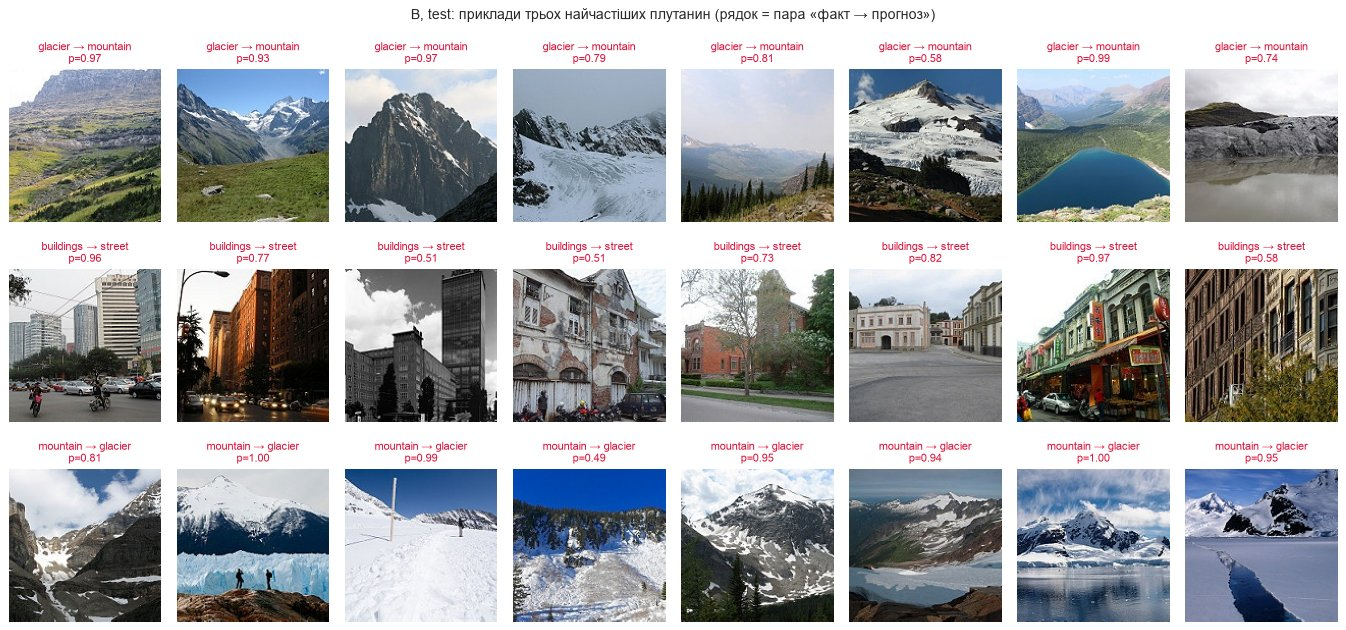

In [36]:
pb = PRED['B', 'test']
top3 = top_confusions(pb, k=3)
err_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(top3), 8, figsize=(16, 2.6 * len(top3)), squeeze=False)
for r, (_, row) in enumerate(top3.iterrows()):
    t, y = CLASSES.index(row['факт']), CLASSES.index(row['прогноз'])
    idx = np.flatnonzero((pb['y_true'] == t) & (pb['y_pred'] == y))
    chosen = err_rng.choice(idx, min(8, len(idx)), replace=False)
    for c in range(8):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(chosen):
            i = chosen[c]
            ax.imshow(load_rgb(SPLIT_PATHS['test'][i]))
            ax.set_title(f'{CLASSES[t]} → {CLASSES[y]}\np={pb["probs"][i, y]:.2f}', fontsize=9, color='crimson')
fig.suptitle('B, test: приклади трьох найчастіших плутанин (рядок = пара «факт → прогноз»)', fontsize=12)
plt.tight_layout()
show_photos(fig)

### 11.3 Найвпевненіші помилки: кандидати на шум у мітках

Помилки, де модель дає прогнозованому класу ймовірність близьку до 1, часто виявляються помилками розмітки або неоднозначними сценами. Позначка `[дубль]` означає, що файл має побайтову копію з іншою міткою (розділ 3.4).

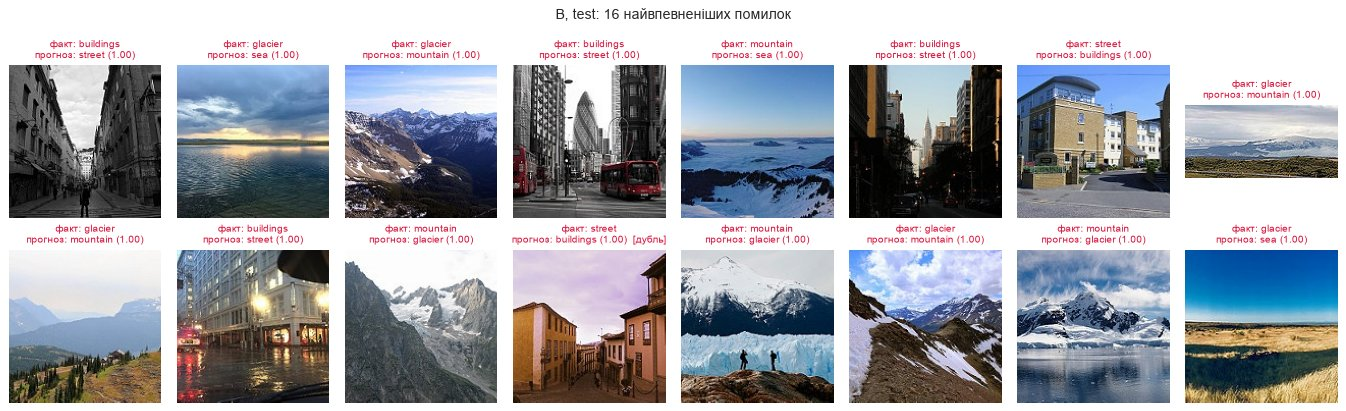

Помилок B з ймовірністю прогнозу > 0.9: 71 з 175
Тестові файли з конфліктним дублікатом у train: 3; з них B помиляється на: 3


In [37]:
wrong = np.flatnonzero(pb['y_true'] != pb['y_pred'])
conf_wrong = wrong[np.argsort(-pb['probs'][wrong, pb['y_pred'][wrong]])][:16]
show_grid(SPLIT_PATHS['test'],
          pred_items(pb, conf_wrong, extra=lambda i: '  [дубль]' if SPLIT_PATHS['test'][i] in CONFLICT_TEST_FILES else ''),
          title='B, test: 16 найвпевненіших помилок')
print(f'Помилок B з ймовірністю прогнозу > 0.9: {(pb["probs"][wrong, pb["y_pred"][wrong]] > 0.9).sum()} з {len(wrong)}')
dup_idx = [i for i, path in enumerate(SPLIT_PATHS['test']) if path in CONFLICT_TEST_FILES]
print(f'Тестові файли з конфліктним дублікатом у train: {len(dup_idx)}; з них B помиляється на: '
      f'{sum(pb["y_true"][i] != pb["y_pred"][i] for i in dup_idx)}')

### 11.4 Якість за класами та впевненість моделей

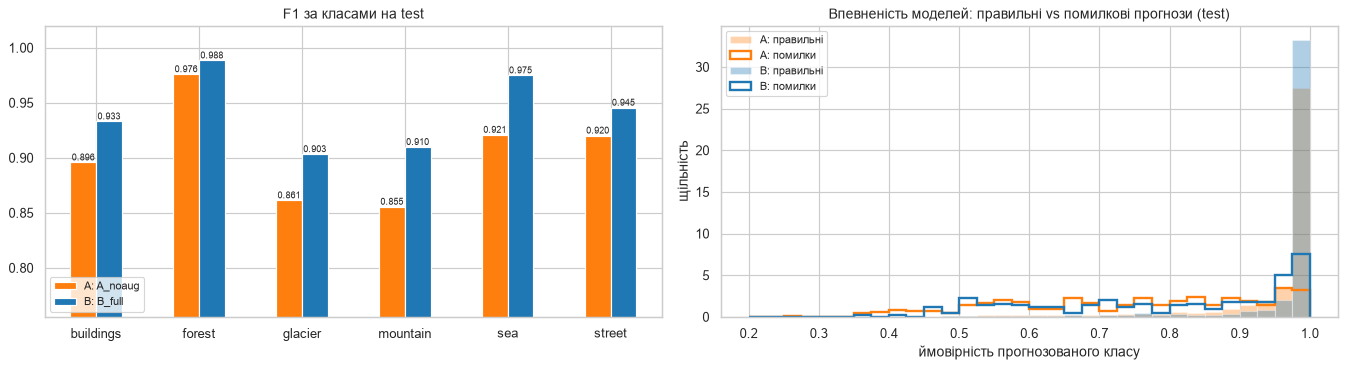

,A: A_noaug,B: B_full
buildings,0.8958,0.9330
forest,0.9759,0.9884
glacier,0.8613,0.9033
mountain,0.8555,0.9098
sea,0.9208,0.9749
street,0.9202,0.9455


In [38]:
per_class = pd.DataFrame({k: f1_score(PRED[k, 'test']['y_true'], PRED[k, 'test']['y_pred'], average=None, zero_division=0,
                                      labels=range(NUM_CLASSES)) for k in FINAL}, index=CLASSES)
per_class.columns = [f'{k}: {FINAL[k]["name"]}' for k in FINAL]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
per_class.plot.bar(ax=axes[0], color=['tab:orange', 'tab:blue'], rot=0)
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt='%.3f', fontsize=8)
axes[0].set_ylim(per_class.values.min() - 0.1, 1.02)
axes[0].set_title('F1 за класами на test')
axes[0].legend(loc='lower left', fontsize=9)
for k, color in zip(FINAL, ['tab:orange', 'tab:blue']):
    p = PRED[k, 'test']
    conf = p['probs'].max(axis=1)
    ok = p['y_true'] == p['y_pred']
    axes[1].hist(conf[ok], bins=np.linspace(0.2, 1, 33), alpha=0.35, color=color, density=True, label=f'{k}: правильні')
    axes[1].hist(conf[~ok], bins=np.linspace(0.2, 1, 33), histtype='step', lw=2, color=color, density=True, label=f'{k}: помилки')
axes[1].set_xlabel('ймовірність прогнозованого класу')
axes[1].set_ylabel('щільність')
axes[1].set_title('Впевненість моделей: правильні vs помилкові прогнози (test)')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()
display(per_class.style.format('{:.4f}'))

### 11.5 Висновки аналізу помилок

1. Дві пари класів дають ~79 % помилок B: `glacier ↔ mountain` 85 зі 175 (48.6 %), `buildings ↔ street` 53 (30.3 %). Далі йдуть `glacier ↔ sea` (12) і `mountain ↔ sea` (9). У A найбільше помилок у тих самих двох парах (105 і 64, тобто 36 % і 22 %), але частка плутанин із `sea` помітно більша (`glacier ↔ sea` 32, `mountain ↔ sea` 26, разом 20 %). Мережа з нуля більше покладається на колір (біло-блакитна гама), а претренована ResNet18 краще розпізнає форму рельєфу й текстуру льоду та води.
2. Плутанини виникають через семантичне перекриття класів. На фото льодовика майже завжди є гори, а гори часто засніжені. Вулиця складається з будівель, а будівлі найчастіше знімають з вулиці. Межу між класами визначає домовленість розмітника (що «переважає» в кадрі), а не чітка візуальна ознака. За змістом задача ближча до multi-label, але розмічена як single-label.
3. Шум у мітках. 71 зі 175 помилок B зроблені з упевненістю > 0.9, і серед 16 найвпевненіших помилок більшість має явно сумнівні мітки: типові гірські пейзажі з міткою `glacier`, морський горизонт на заході сонця з міткою `glacier`, «море хмар» з міткою `mountain`, вулиці з міткою `buildings`. Усі 3 тестові файли, що мають побайтову копію в train з іншою міткою, «помилкові» для B, бо модель відтворює train-мітку. Отже, частина «помилок» є помилками розмітки, і 100 % на цьому test недосяжні в принципі.
4. Впевненість. Переважна більшість правильних прогнозів B має ймовірність > 0.95, а помилки розподілені по всьому діапазону 0.4-1.0. Низька впевненість (< 0.6) корисна як сигнал для ручної перевірки, але «впевнених» помилок через шум міток вона не виявляє.
5. `forest` майже ні з чим не плутається (F1 0.98-0.99 в обох моделей): клас з унікальною текстурою розділяє навіть модель з нуля.

## 12. Прогноз на немаркованих зображеннях `seg_pred`

`seg_pred` не має міток, тому точність тут не порахувати. Розділ показує, як фінальна модель B працює на нових зображеннях (як у продакшені), і перевіряє, що розподіл прогнозів правдоподібний. Файли лежать без підпапок класів, тому замість `ImageFolder` я використовую мінімальний `Dataset` зі списку шляхів (`num_workers=0`, бо клас визначено в ноутбуці).

,прогнозів,%,"test, % (довідково)"
buildings,1101,15.1,14.6
forest,1178,16.1,15.8
glacier,1203,16.5,18.4
mountain,1351,18.5,17.5
sea,1195,16.4,17.0
street,1273,17.4,16.7


Зображень: 7,301; частка прогнозів з ймовірністю < 0.6 (невпевнені): 2.2 %


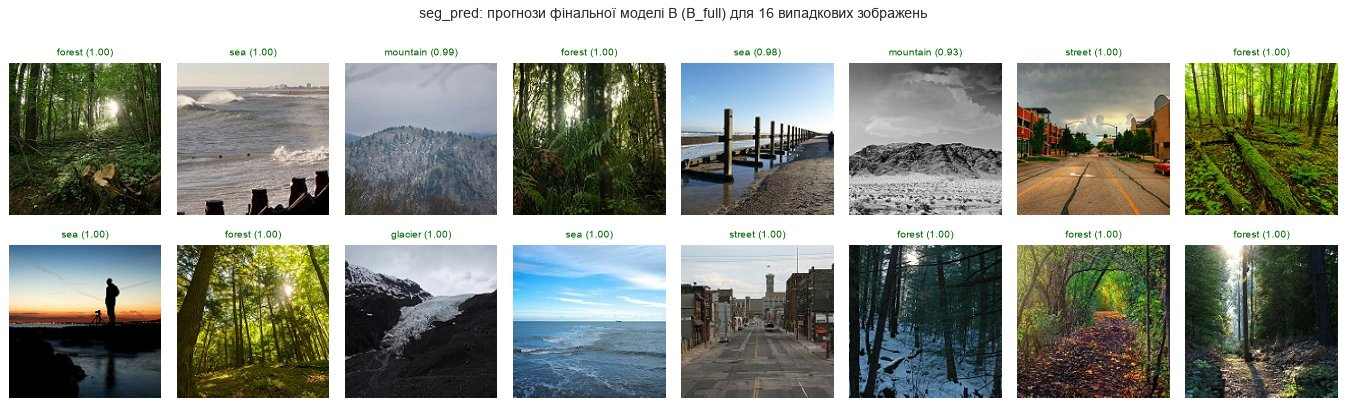

In [39]:
class ImageListDataset(Dataset):
    """Unlabelled images from a list of paths (label = -1)."""

    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.transform(datasets.folder.default_loader(self.paths[i])), -1


pred_eval_tf = final_B['data']['test'].dataset.transform       # the same deterministic pipeline as for test
pred_ds = ImageListDataset(pred_files, pred_eval_tf)
final_B['model'].eval()
pred_probs = []
with torch.no_grad():
    for x, _ in DataLoader(pred_ds, batch_size=128, num_workers=0):
        pred_probs.append(torch.softmax(final_B['model'](x.to(DEVICE)), dim=1).cpu())
pred_probs = torch.cat(pred_probs).numpy()
pred_labels = pred_probs.argmax(axis=1)

dist = pd.DataFrame({'прогнозів': np.bincount(pred_labels, minlength=NUM_CLASSES)}, index=CLASSES)
dist['%'] = dist['прогнозів'] / len(pred_labels) * 100
dist['test, % (довідково)'] = counts['test, %']
display(dist.style.format({'%': '{:.1f}', 'test, % (довідково)': '{:.1f}'}))
print(f'Зображень: {len(pred_labels):,}; частка прогнозів з ймовірністю < 0.6 (невпевнені): {(pred_probs.max(1) < 0.6).mean() * 100:.1f} %')

sample = np.random.default_rng(SEED).choice(len(pred_files), 16, replace=False)
show_grid(pred_files, [(i, f'{CLASSES[pred_labels[i]]} ({pred_probs[i].max():.2f})', True) for i in sample],
          title=f'seg_pred: прогнози фінальної моделі B ({final_B["name"]}) для 16 випадкових зображень')

## 13. Висновки

Фінальні моделі обрано за val macro-F1, test використано один раз.

| Модель | Параметрів | Час навчання (MPS) | val accuracy / macro-F1 | test accuracy / macro-F1 | Орієнтир з умови |
|---|---|---|---|---|---|
| A: CNN з нуля (`A_noaug`, обрана за val) | 1.2 млн | 15.5 хв | 0.911 / 0.912 | 0.904 / 0.905 | 75-85 % / 0.73-0.83 |
| B: ResNet18, етап 1 + повний fine-tuning (`B_full`) | 11.2 млн | 8.5 хв (разом з етапом 1) | 0.945 / 0.946 | 0.942 / 0.943 | 90-97 % / 0.89-0.96 |

### Основні висновки

1. Обидві моделі досягли орієнтирів з умови. B потрапила в діапазон для transfer learning, A навіть перевищила діапазон для CNN з нуля.
2. Трансферне навчання виграє за всіма критеріями: +3.8 п.п. accuracy на test, на 39 % менше помилок, швидше навчання. Навіть лінійна голова на заморожених ознаках ImageNet за 1 хв (val F1 0.918) краща за мережу з нуля, яка вчилася 15-17 хв (0.908-0.912).
3. Мережа з нуля досягає ~90 % завдяки BatchNorm, GAP замість Flatten і зменшенню lr на плато. Ефект аугментацій за 25 епох лежить у межах розкиду між запусками, але вони помітно зменшують запамʼятовування train і лишають запас для довшого навчання.
4. У TL найбільше дає fine-tuning хоча б останнього блоку (+2.5 п.п. до замороженого backbone). Розморожування всієї мережі додає ще лише +0.3 п.п. (у межах похибки), а збільшення входу до 224×224 дає +0.75 п.п. (для замороженого backbone +1.75 п.п.).
5. Залишкові помилки зосереджені у двох семантично перекритих парах класів (`glacier`/`mountain` і `buildings`/`street`, разом ~79 % помилок B). Значною мірою їх пояснює шум у мітках (13 конфліктних дублікатів, упевнені «помилки» на явно неправильно розмічених фото), а не нестача ємності моделі.

### Критика та обмеження

* A є простою VGG-подібною мережею без skip-звʼязків. При lr 1e-3 валідація нестабільна, і результат залежить від запуску (див. розділ 8). Варіант з аугментаціями ще недонавчений.
* B сильно перенавчається (train 99.6 % vs val 94.5 %). Стримують це лише короткий fine-tuning, аугментації та вибір чекпойнта.
* Кожну конфігурацію навчено один раз (один seed, один поділ train/val), а обчислення на MPS не повністю детерміновані, тому різниці < 0.5 п.п. статистично не значущі. Бюджет навчання обмежений через час (≤ 25 / 3 + 6 епох).
* Test містить помилки розмітки, а вихідна роздільна здатність 150×150 обмежує дрібні деталі (текстура льоду vs снігу).

### Конкретні покращення

Список упорядковано за очікуваним ефектом на цих даних.

1. Стійкість до шуму міток: `CrossEntropyLoss(label_smoothing=0.1)`, MixUp/CutMix, очищення train за принципом confident learning (напр., через `cleanlab` переглянути найвпевненіші помилки на out-of-fold прогнозах), видалення 13 конфліктних дублікатів, окремий звіт на «очищеному» test.
2. Сильніший backbone: EfficientNet-B0/B2, ConvNeXt-Tiny або ResNet50 (очікувано +1-2 п.п.), а також ансамбль 2-3 моделей або сідів.
3. Кращий режим fine-tuning: AdamW з косинусним розкладом і warmup, дискримінативні lr (менші для ранніх шарів), 10-15 епох із сильнішими аугментаціями (TrivialAugment / RandAugment, RandomErasing).
4. TTA, тобто усереднення прогнозів для оригіналу та горизонтального відображення. Зазвичай це дає +0.2-0.5 п.п. без донавчання.
5. Для A: 35-40 епох з аугментаціями та `OneCycleLR` або косинусним розкладом (валідація стабільніша, ніж при сталому lr 1e-3), residual-блоки, ширші канали.
6. Постановка задачі. Сцени часто містять кілька класів, тому варто розглянути multi-label або ієрархію (природа / місто). У продакшені можна ввести поріг упевненості й передавати невпевнені прогнози (< 0.6, ~2 % `seg_pred`) на ручну перевірку.
7. Надійніше порівняння конфігурацій: кілька сідів або k-fold крос-валідація з довірчими інтервалами.

In [40]:
print(f'Пристрій: {DEVICE}; загальний час виконання ноутбука: {(time.time() - NOTEBOOK_START) / 60:.1f} хв')
display(pd.DataFrame([{k: r['summary'][k] for k in ('run', 'варіант', 'val macro-F1', 'час навчання, хв')}
                      for r in RUNS.values()]).set_index('run')
        .style.format({'val macro-F1': '{:.4f}', 'час навчання, хв': '{:.1f}'}))

Пристрій: mps; загальний час виконання ноутбука: 48.9 хв


,варіант,val macro-F1,"час навчання, хв"
run,,,
A_aug,A,0.9078,16.8
B_head,B,0.9176,1.0
B_layer4,B,0.9430,3.4
A_noaug,A,0.9122,15.5
B_full,B,0.9457,8.5
B_head150,B,0.9001,0.8
B_full150,B,0.9382,4.3
